### Lectura de datos

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
def leer_estacion_excel(ruta_archivo, hoja = "Sheet1"):
    """
    Lee un archivo Excel con datos psicrométricos y los carga en un DataFrame.
    'hoja' puede ser el número de la pestaña (0 para la primera hasta n-1) o su nombre exacto (ej. "Datos1").
    """
    try:
        # Lee el xlsx estructurado como una tabla, usando el separador ya definido
        df = pd.read_excel(ruta_archivo, sheet_name = hoja, skiprows = 2) #, index_col = 'Timestamp'
        print(f"-> Archivo Excel '{ruta_archivo}' leído exitosamente.")
        return df
    except Exception as e:
        print(f"Error al leer el archivo Excel: {e}")
        return None

In [3]:
def leer_dias_riego(ruta_archivo):
    """
    Lee un archivo txt con fechas y los carga en un DataFrame.
    """
    try:
        # Lee el txt estructurado como una tabla, usando el separador ya definido
        df = pd.read_csv(ruta_archivo, names = ['Fecha'])
        print(f"-> Archivo txt '{ruta_archivo}' leído exitosamente.")
        return df
    except Exception as e:
        print(f"Error al leer el archivo txt: {e}")
        return None

In [4]:
ruta_est = '/home/alejandro/labtesis/DATA - acotada/z6-13472_acotado_01Abr_14Jul.xlsx'
df_est = leer_estacion_excel(ruta_est)
df_est
# Para ver unicamente los valores numericos puedo usar la funcion .iloc[fila:] ... por ejemplo df_est.iloc[2:]

-> Archivo Excel '/home/alejandro/labtesis/DATA - acotada/z6-13472_acotado_01Abr_14Jul.xlsx' leído exitosamente.


,Timestamp,°C Air Temperature,RH Relative Humidity,kPa Atmospheric Pressure,m³/m³ Water Content,°C Soil Temperature,mS/cm Bulk EC,° Wind Direction,m/s Wind Speed,m/s Gust Speed,...,° X-axis Level,° Y-axis Level,W/m² Solar Radiation,µmol·m⁻²·s⁻¹ PPFD,kPa Matric Potential,°C Soil Temperature.1,% Battery Percent,mV Battery Voltage,kPa Reference Pressure,°C Logger Temperature
0,2026-04-01 00:00:00,14.10,0.908725,75.36,0.132140,16.40,0.052000,186,0.04,0.07,...,-1.6,0.3,0.0,0.0,-10.700289,17.60,100,7908,75.30,13.98
1,2026-04-01 00:05:00,14.16,0.911394,75.36,0.132411,16.40,0.051761,239,0.04,0.06,...,-1.6,0.3,0.0,0.0,-10.700289,17.60,100,7893,75.30,14.06
2,2026-04-01 00:10:00,14.18,0.908976,75.35,0.132373,16.36,0.052000,171,0.03,0.06,...,-1.7,0.3,0.0,0.0,-10.700289,17.58,100,7901,75.28,14.08
3,2026-04-01 00:15:00,14.12,0.910654,75.34,0.132411,16.30,0.052000,198,0.04,0.07,...,-1.7,0.3,0.0,0.0,-10.700289,17.50,100,7900,75.28,14.02
4,2026-04-01 00:20:00,14.12,0.906927,75.35,0.132295,16.30,0.051761,251,0.07,0.12,...,-1.7,0.2,0.0,0.0,-10.700289,17.50,100,7901,75.29,14.02
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30233,2026-07-14 23:35:00,12.08,0.881507,75.53,0.341839,18.90,0.028774,213,0.08,0.14,...,2.5,1.8,0.0,0.0,-0.097993,18.60,100,7971,75.46,12.19
30234,2026-07-14 23:40:00,12.12,0.888391,75.52,0.341800,18.90,0.028774,243,0.07,0.13,...,2.3,1.7,0.0,0.0,-0.097993,18.50,100,7974,75.46,12.25
30235,2026-07-14 23:45:00,12.18,0.891940,75.52,0.341916,18.90,0.028774,219,0.08,0.20,...,2.5,1.7,0.0,0.0,-0.097993,18.50,100,7972,75.45,12.27
30236,2026-07-14 23:50:00,12.20,0.891471,75.52,0.341877,18.90,0.028973,223,0.07,0.11,...,2.4,1.8,0.0,0.0,-0.097993,18.50,100,7975,75.45,12.22


In [5]:
# Para ver el nombre de las columnas
print(df_est.columns.tolist())

['Timestamp', '°C Air Temperature', 'RH Relative Humidity', 'kPa Atmospheric Pressure', 'm³/m³ Water Content', '°C Soil Temperature', 'mS/cm Bulk EC', '° Wind Direction', 'm/s Wind Speed', 'm/s Gust Speed', '°C Anemometer Temp', '° X-axis Level', '° Y-axis Level', 'W/m² Solar Radiation', 'µmol·m⁻²·s⁻¹ PPFD', 'kPa Matric Potential', '°C Soil Temperature.1', '% Battery Percent', 'mV Battery Voltage', 'kPa Reference Pressure', '°C Logger Temperature']


In [6]:
ruta = "/home/alejandro/labtesis/DATA - acotada/riego.txt"
df_riego = leer_dias_riego(ruta)
#df_riego

-> Archivo txt '/home/alejandro/labtesis/DATA - acotada/riego.txt' leído exitosamente.


In [7]:
print(df_riego.columns.tolist())

['Fecha']


### Conversion de cadenas de caracteres a datetime (fecha de Pandas)

In [8]:
# Convertir las columnas de los DataFrame a formato fecha, aceptado por Pandas

# Convertir df_est (mantenemos coercing por seguridad)
df_est["Timestamp"] = pd.to_datetime(df_est["Timestamp"], errors="coerce")
df_est = df_est.dropna(subset=["Timestamp"])

# Especificar el formato exacto de fecha (ej. 15/03/2026)
df_riego["Fecha"] = pd.to_datetime(df_riego["Fecha"], format="%d/%m/%Y", errors="coerce")
df_riego = df_riego.dropna(subset=["Fecha"])

#if df_est.index.name == "Timestamp":
#    df_est = df_est.reset_index()

# El parametro errors="coerce" lo que hace es convertir a NaN cualquier fecha que no haya podido ser leida
# La funcion dropna lo que hace es descartar las fechas que esten como cualquuier formato diferente de una fecha valida
#df_riego

### Graficas con datos crudos

In [9]:
def graficar_dos_var (df_est, color1, color2, ylabel1, ylabel2, var1, var2, posley, titulo, df_riego = None, ley1 = "", ley2 = ""):

    # Crear lienzo
    fig, ax = plt.subplots(figsize=(18, 9))
    
    # Cuadricula
    ax.grid(True, linestyle = "--", alpha=0.5)
    
    # Crear eje X y Y
    ax.set_xlabel("Fecha", fontsize = 11, fontweight = "bold")
    ax.set_ylabel(ylabel1, fontsize = 10, fontweight = "bold", color = color1)
    fig1 = ax.plot(df_est["Timestamp"], df_est[var1], linewidth = 1.2, label = ylabel1, color = color1)
    ax.tick_params(axis = "y", labelcolor = color1) # Cambia el color de los numeros y marcas de graduacion del eje y

    if var2: 
        # Segundo eje Y que comparte X... por lo que no es necesario usar de nuevo ax.set_xlabel()
        if ylabel1 != ylabel2:
            ax1 = ax.twinx()
        else:
            ax1 = ax
        ax1.set_ylabel(ylabel2, fontsize = 10, fontweight = "bold", color = color2)
        fig2 = ax1.plot(df_est["Timestamp"], df_est[var2], linewidth = 1.2, label = ylabel2, color = color2)
        ax1.tick_params(axis = "y", labelcolor = color2)

    # Lineas verticales
    if df_riego is not None: 
        for fecha in df_riego["Fecha"]:  
            ax.axvline(x = pd.Timestamp(fecha), color = "skyblue", linestyle = ":")
    
    # Si uso ax.legeng() y ax1.legeng() se solapan... entonces
    if var2:
        figg = fig1 + fig2
        # Si se pasaron textos personalizados en ley1 y ley2, se usan directamente
        if ley1 and ley2:
            labels = [ley1, ley2]
        else:
            labels = [l.get_label() for l in figg]
    else:
        figg = fig1
        # Si solo hay una variable pero ley1 tiene texto
        if ley1:
            labels = [ley1]
        else:
            labels = [l.get_label() for l in figg]

    ax.legend(figg, labels, loc = posley)
            
    # Titulo de la grafica
    plt.title(
        titulo,
        fontsize = 13,
        fontweight = "bold",
    )
    
    fig.tight_layout() # Buena practica para evitar errores graficos
    
    plt.show()

In [10]:
# Para ver más colores https://matplotlib.org/3.1.1/gallery/color/named_colors.html
var_pares = {
    "hum_suelo_vol_ec": {
        "color1": "cornflowerblue",
        "color2": "slateblue",
        "ylabel1": "Contenido de agua volumétrico [m³/m³]",
        "ylabel2": "Conductividad eléctrica [mS/cm]",
        "var1": 'm³/m³ Water Content',
        "var2": 'mS/cm Bulk EC',
        "posley": "lower center",
        "titulo": "Humedad del suelo",
        "ley1": "",
        "ley2": "",
    },
    "hum_suelo_vol_pot": {
        "color1": "royalblue",
        "color2": "saddlebrown",
        "ylabel1": "Contenido de agua volumétrico [m³/m³]",
        "ylabel2": "Potencial Mátrico [kPa]",
        "var1": 'm³/m³ Water Content',
        "var2": 'kPa Matric Potential',
        "posley": "lower center",
        "titulo": "Humedad del suelo",
        "ley1": "",
        "ley2": "",
    },
    "hum_suelo_ce_pot": {
        "color1": "slateblue",
        "color2": "saddlebrown",
        "ylabel1": "Conductividad eléctrica [mS/cm]",
        "ylabel2": "Potencial Mátrico [kPa]",
        "var1": 'mS/cm Bulk EC',
        "var2": 'kPa Matric Potential',
        "posley": "lower center",
        "titulo": "Humedad del suelo",
        "ley1": "",
        "ley2": "",
    },
    "temp_suelo":{
        "color1": "chocolate",
        "color2": "steelblue",
        "ylabel1": "Temperatura del suelo [°C]",
        "ylabel2": "Temperatura del suelo [°C]",
        "var1": '°C Soil Temperature',
        "var2": '°C Soil Temperature.1',
        "posley": "lower center",
        "titulo": "Temperatura del suelo",
        "ley1": "Temperatura del suelo [°C] Z1",
        "ley2": "Temperatura del suelo [°C] Z2",
    },
    "temp_amb":{
        "color1": "yellowgreen",
        "color2": "",
        "ylabel1": "Temperatura [°C]",
        "ylabel2": "",
        "var1": '°C Air Temperature',
        "var2": '',
        "posley": "lower center",
        "titulo": "Temperatura",
        "ley1": "",
        "ley2": "",
    },
    "hum_rel":{
        "color1": "steelblue",
        "color2": "",
        "ylabel1": "Humedad relativa [%]",
        "ylabel2": "",
        "var1": 'RH Relative Humidity',
        "var2": '',
        "posley": "lower center",
        "titulo": "Humedad relativa",
        "ley1": "",
        "ley2": "",
    },
    "rad_inc":{
        "color1": "forestgreen",
        "color2": "",
        "ylabel1": "Radiación solar [W/m²]",
        "ylabel2": "",
        "var1": 'W/m² Solar Radiation',
        "var2": '',
        "posley": "lower center",
        "titulo": "Radiación solar incidente",
        "ley1": "",
        "ley2": "",
    },
    "rad_fot":{
        "color1": "khaki",
        "color2": "",
        "ylabel1": "Intensidad de luz fotosintéticamente útil [µmol·m⁻²·s⁻¹]",
        "ylabel2": "",
        "var1": 'µmol·m⁻²·s⁻¹ PPFD',
        "var2": '',
        "posley": "lower center",
        "titulo": "Intensidad de luz",
        "ley1": "",
        "ley2": "",
    },
}

--- Configuración de: hum_suelo_vol_ec ---
Título: Humedad del suelo
Variable 1: m³/m³ Water Content y Variable 2: mS/cm Bulk EC


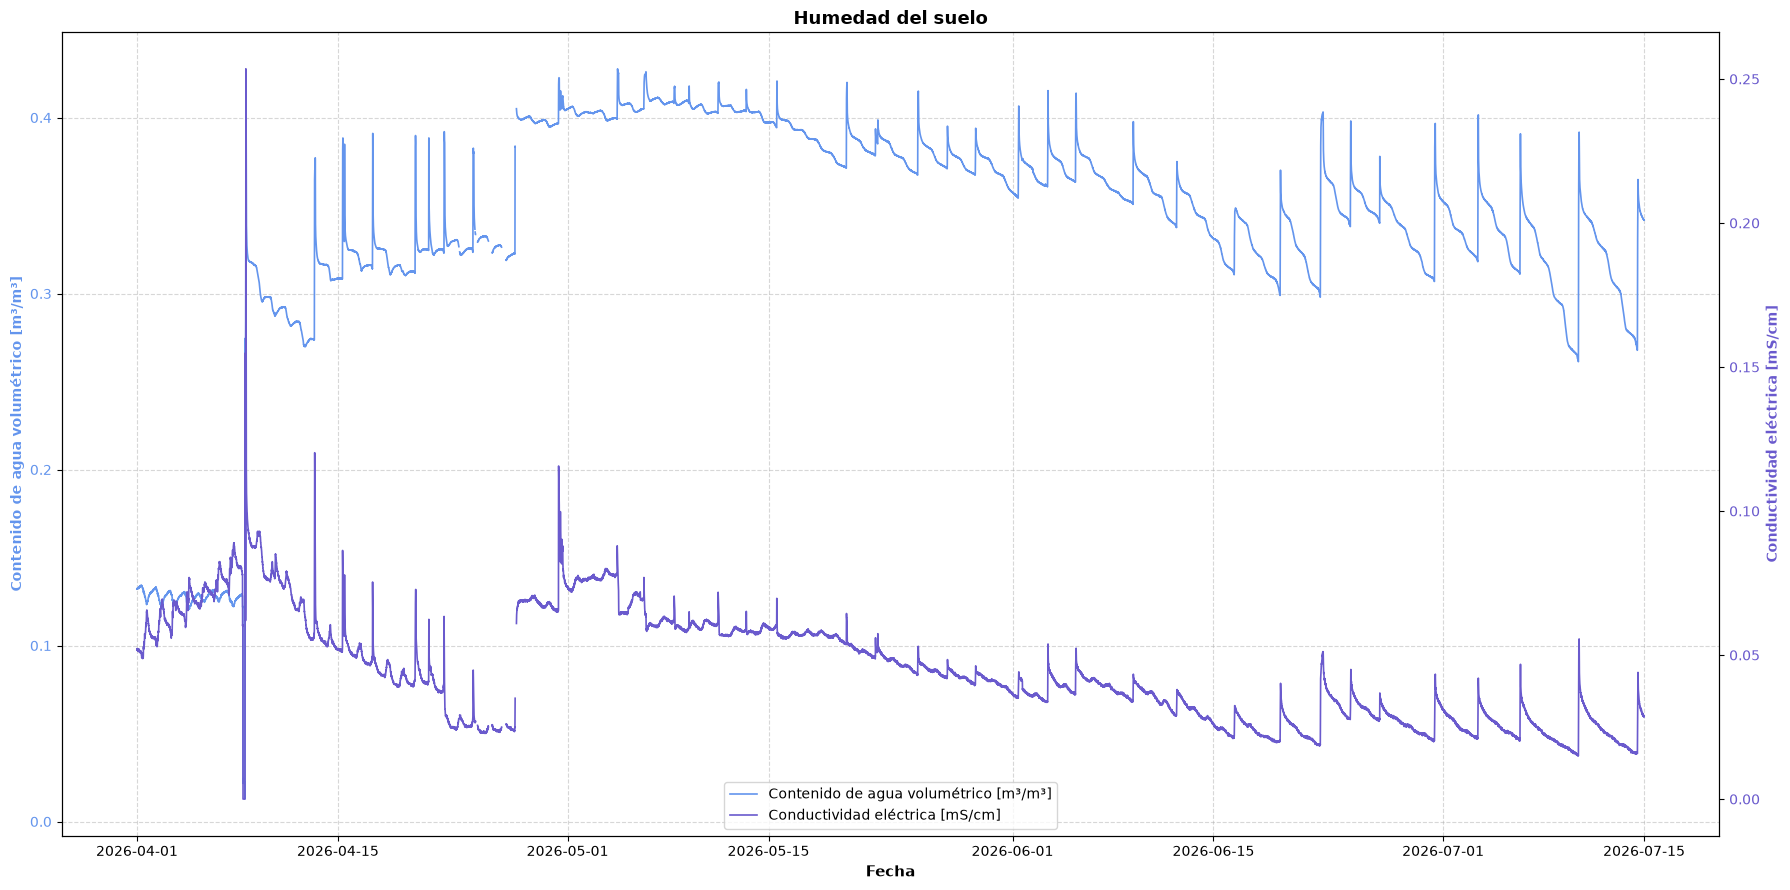

--- Configuración de: hum_suelo_vol_pot ---
Título: Humedad del suelo
Variable 1: m³/m³ Water Content y Variable 2: kPa Matric Potential


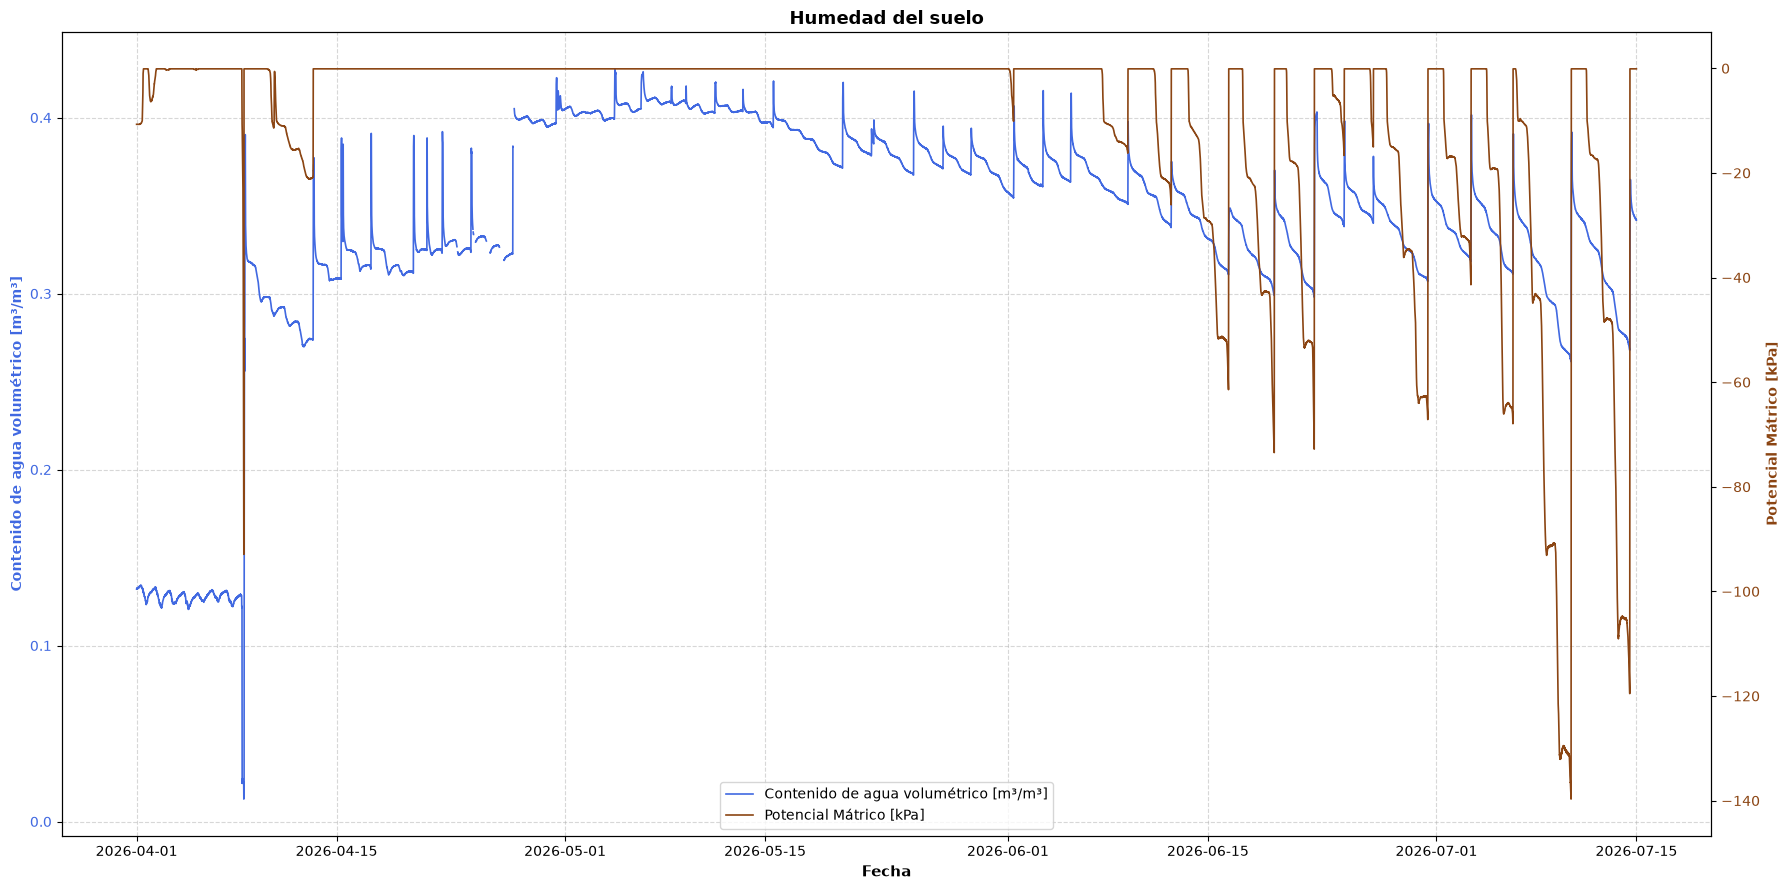

--- Configuración de: hum_suelo_ce_pot ---
Título: Humedad del suelo
Variable 1: mS/cm Bulk EC y Variable 2: kPa Matric Potential


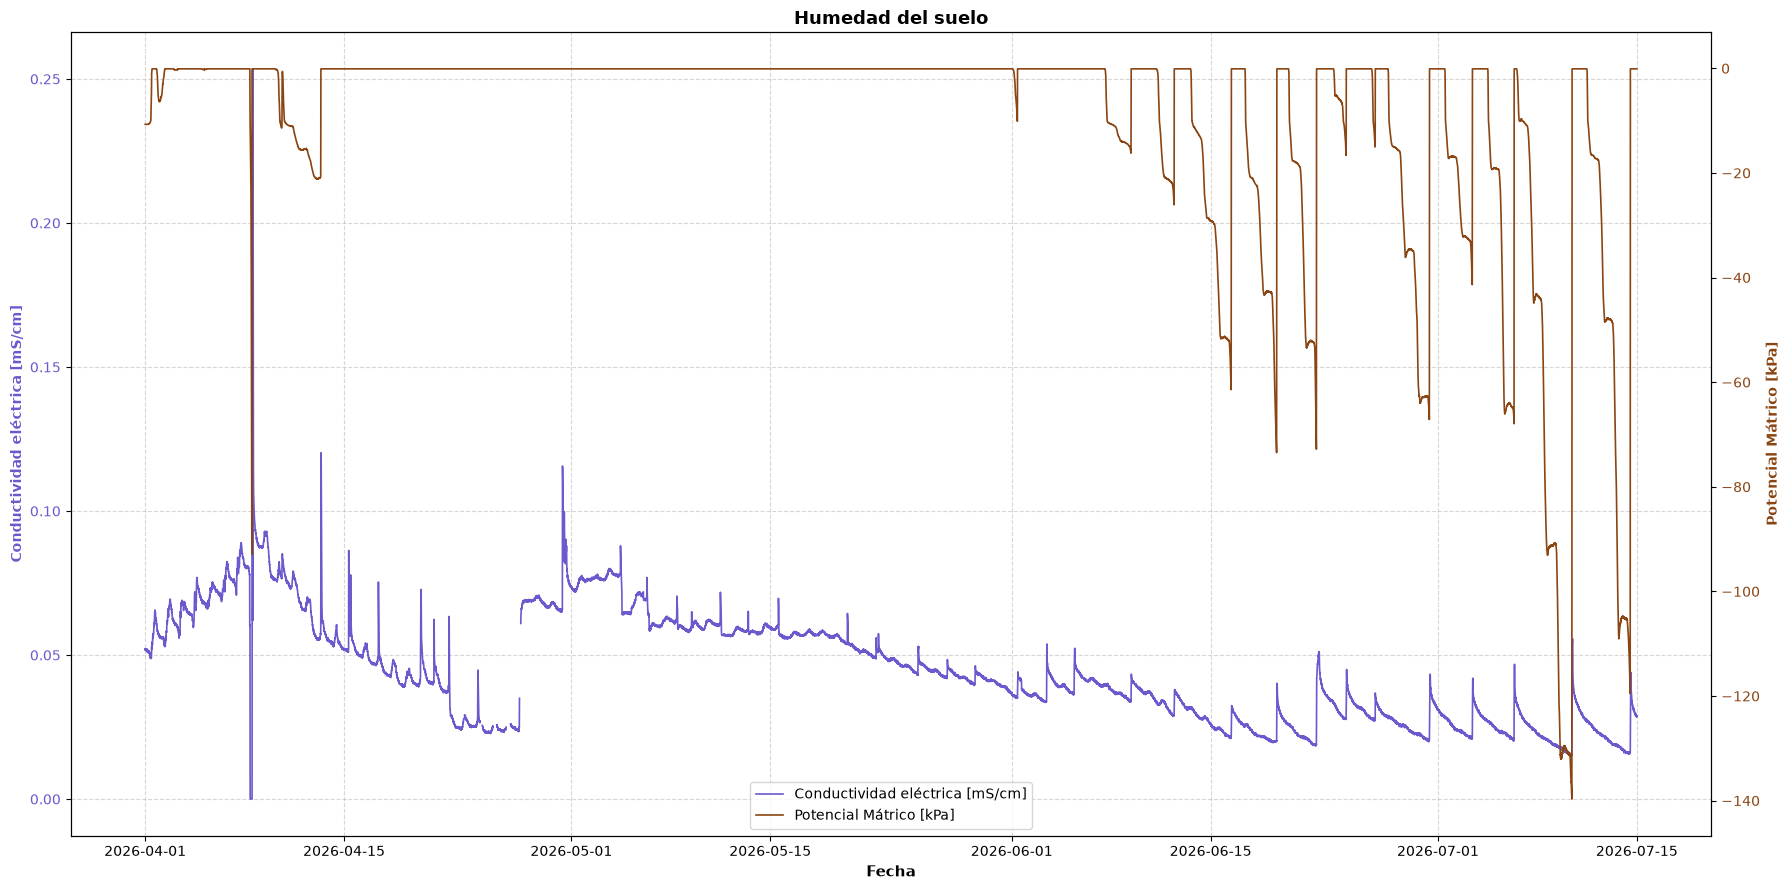

--- Configuración de: temp_suelo ---
Título: Temperatura del suelo
Variable 1: °C Soil Temperature y Variable 2: °C Soil Temperature.1


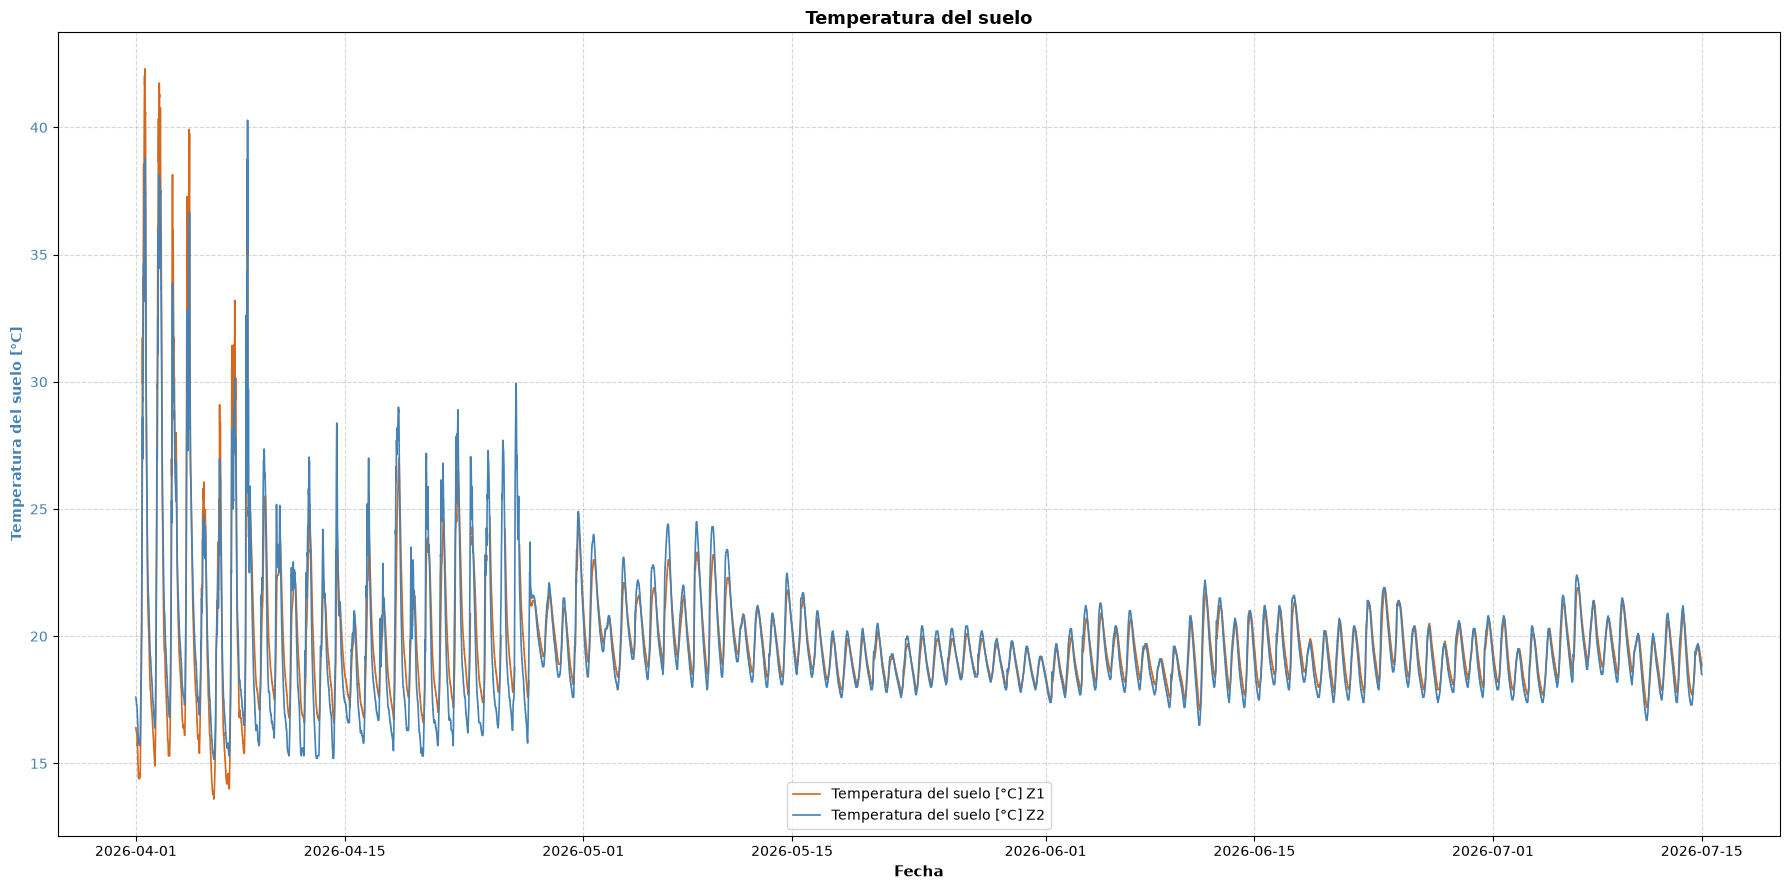

--- Configuración de: temp_amb ---
Título: Temperatura
Variable 1: °C Air Temperature


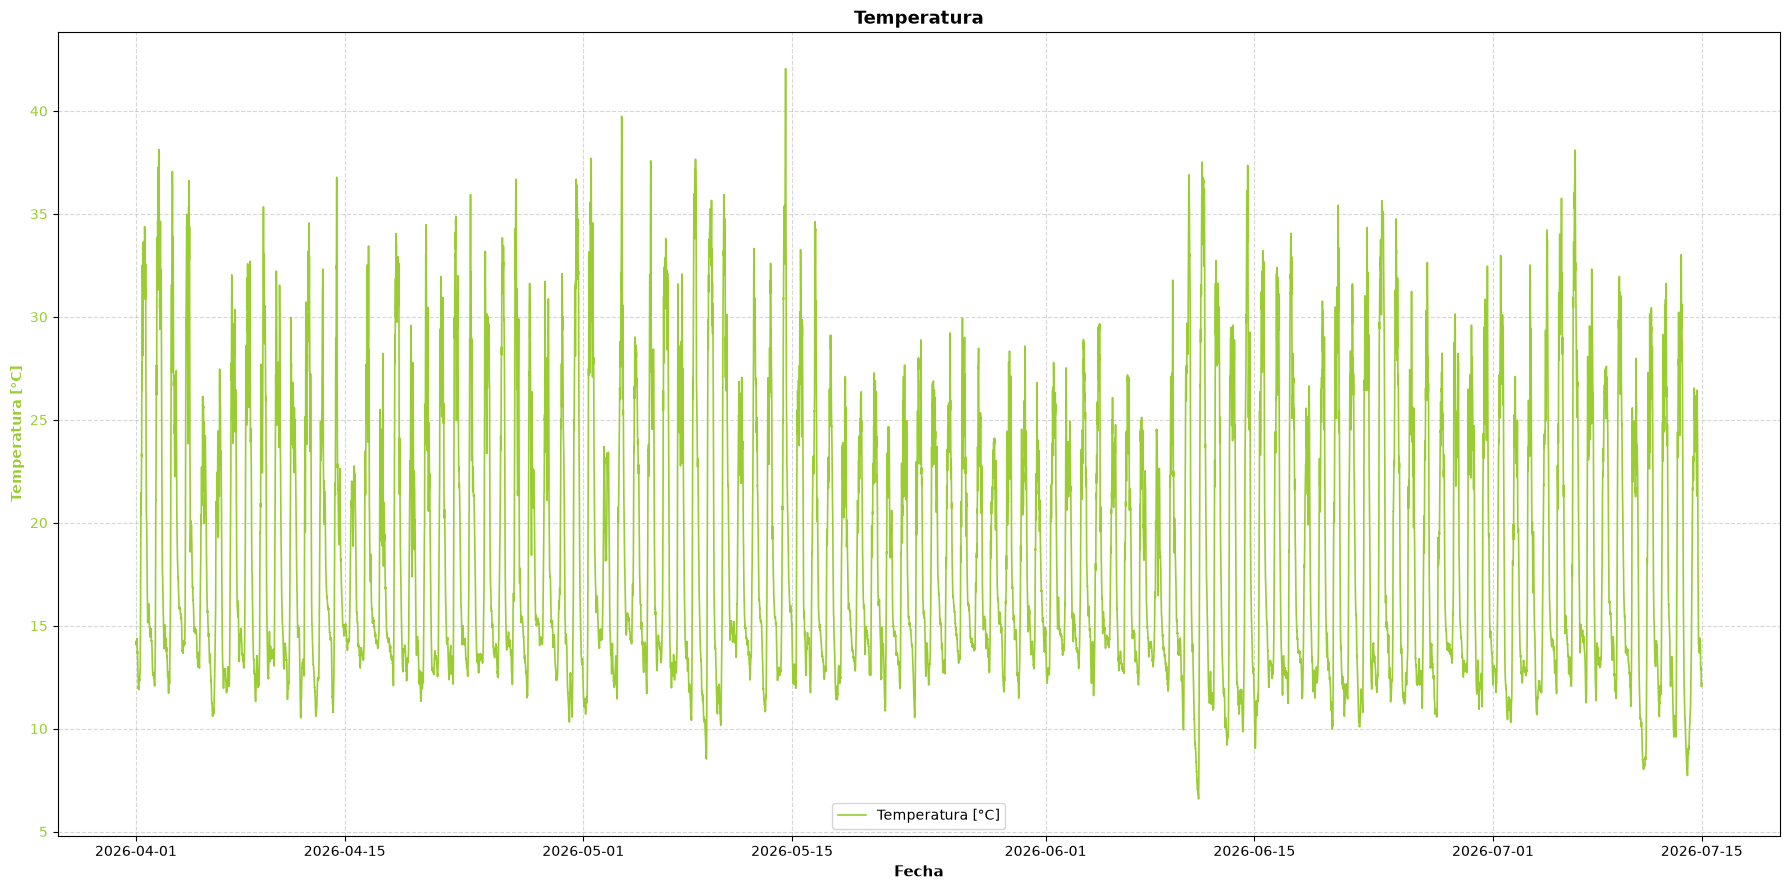

--- Configuración de: hum_rel ---
Título: Humedad relativa
Variable 1: RH Relative Humidity


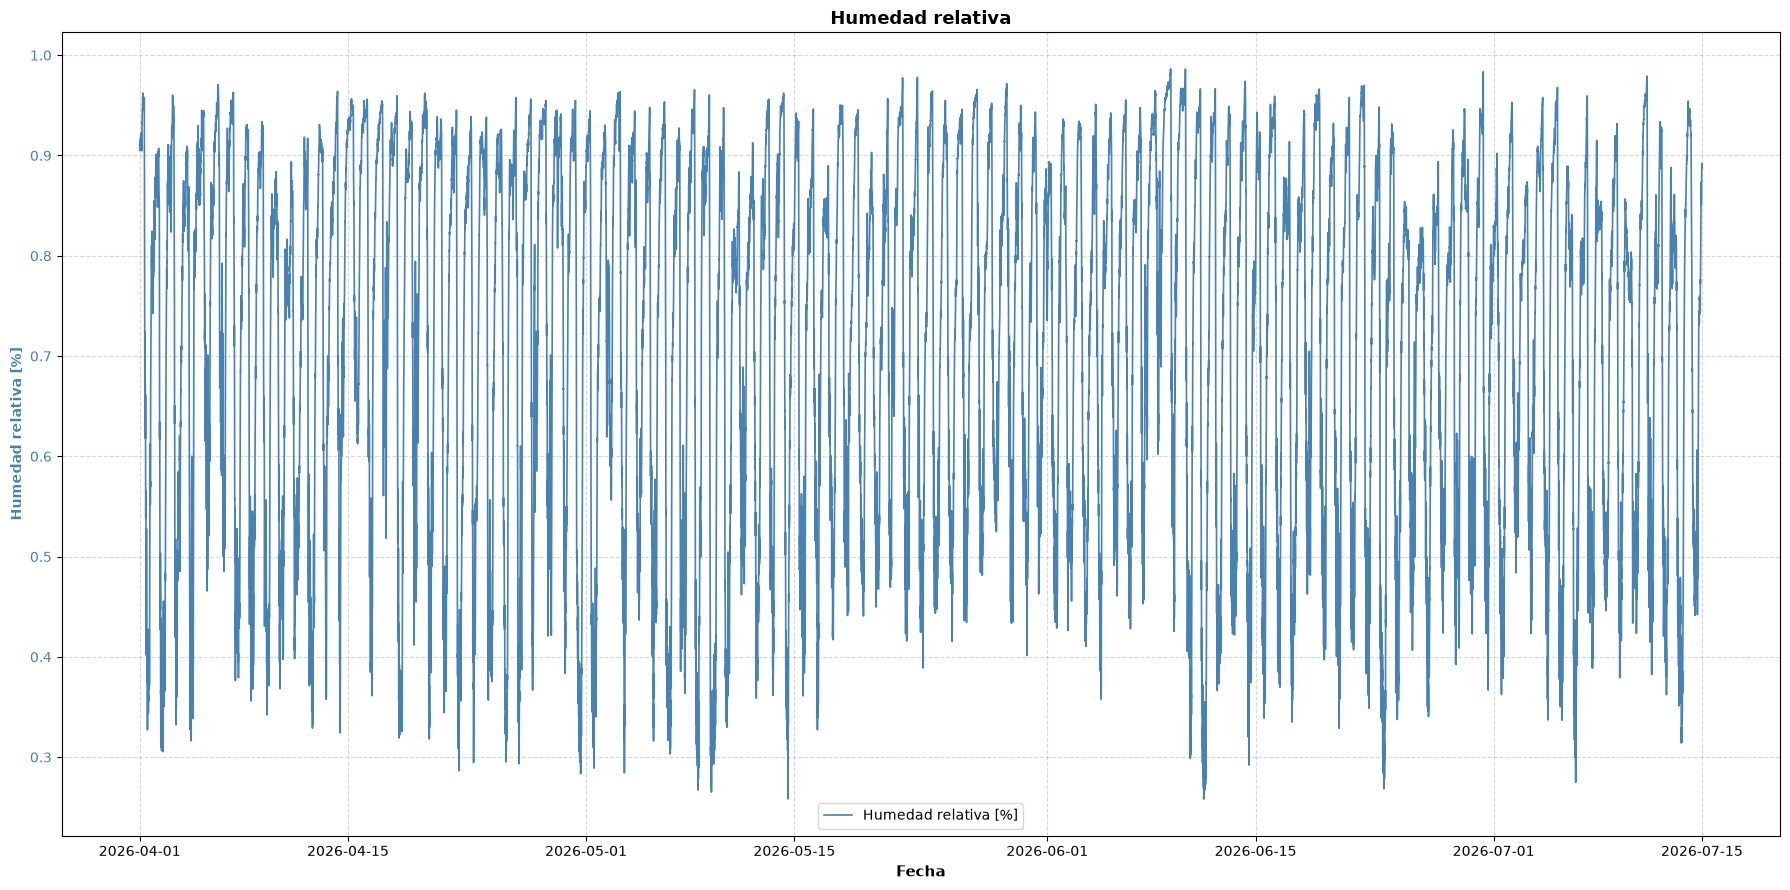

--- Configuración de: rad_inc ---
Título: Radiación solar incidente
Variable 1: W/m² Solar Radiation


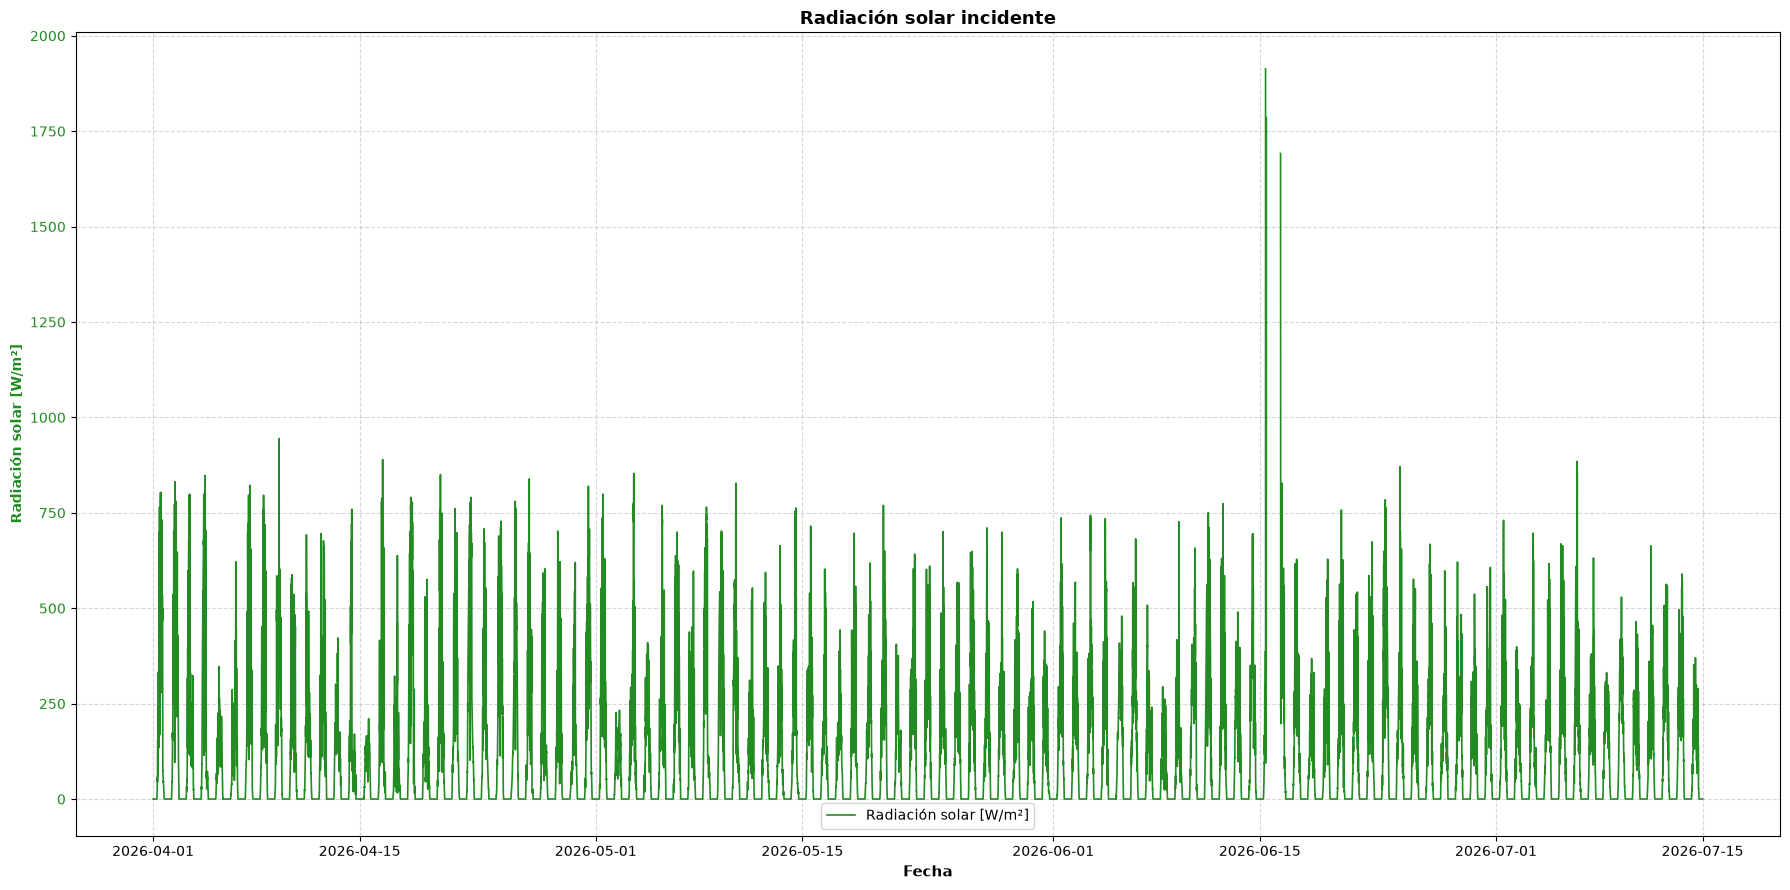

--- Configuración de: rad_fot ---
Título: Intensidad de luz
Variable 1: µmol·m⁻²·s⁻¹ PPFD


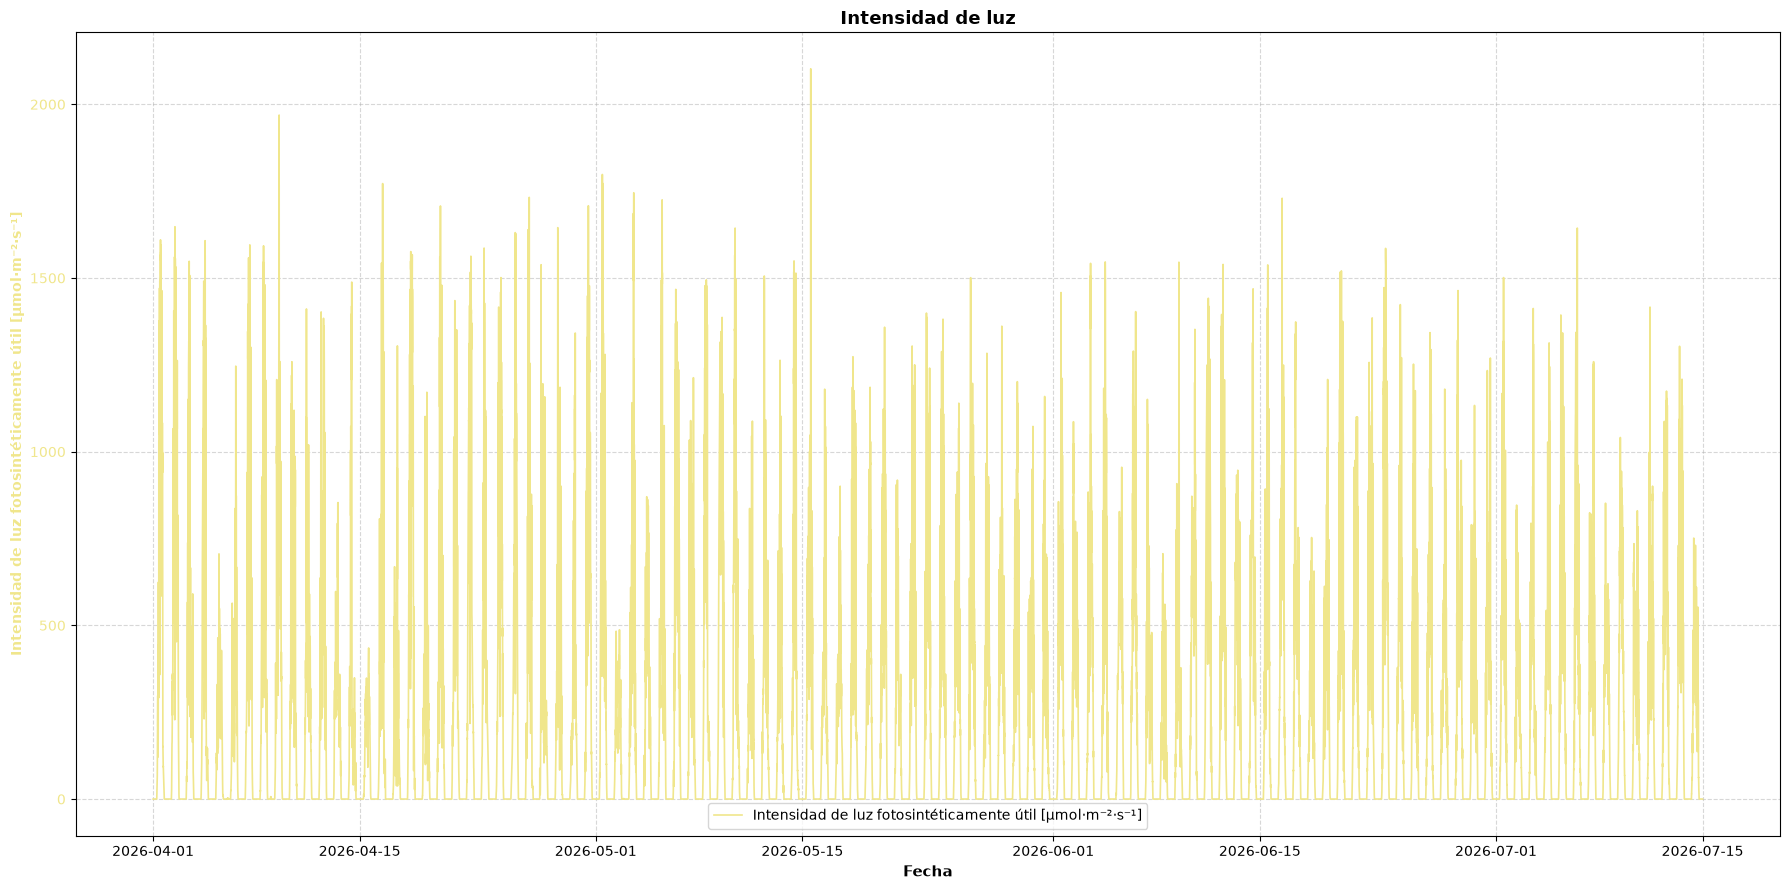

In [11]:
riego = False #Cambiar en caso de querer graficar los dias de reigo

df_riego_g = None

if riego:
    df_riego_g = df_riego

for nombre_grafico, params in var_pares.items():
    print(f"--- Configuración de: {nombre_grafico} ---")
    print(f"Título: {params['titulo']}")
    if params['var2']:
        print(f"Variable 1: {params['var1']} y Variable 2: {params['var2']}")
    else:
        print(f"Variable 1: {params['var1']}")
    graficar_dos_var (df_est, params['color1'], params['color2'], params['ylabel1'], params['ylabel2'], params['var1'], 
                      params['var2'], params['posley'], params['titulo'], df_riego_g, params['ley1'], params['ley2'])

### Garaficas con datos agrupados

In [12]:
# Paleta de colores y titulos para los graficos de la estacion met
var = {
    "°C Air Temperature": {
        "media": "darkred",
        "std": "crimson",
        "amplitud": "coral",
        "titulo": "Comportamiento térmico del aire en el invernadero",
        "eje_y": "Temperatura [°C]",
        "leyenda": "Temp. Aire",
    },
    "RH Relative Humidity": {
        "media": "teal",
        "std": "cadetblue",
        "amplitud": "mediumturquoise",
        "titulo": "Dinámica de la humedad relativa del aire",
        "eje_y": "Humedad Relativa [%]",
        "leyenda": "Humedad Relativa",
    },
    "kPa Atmospheric Pressure": {
        "media": "dimgray",
        "std": "slategray",
        "amplitud": "lightgray",
        "titulo": "Variación de la presión atmosférica local",
        "eje_y": "Presión [kPa]",
        "leyenda": "Presión Atm.",
    },
    "m³/m³ Water Content": {
        "media": "royalblue",
        "std": "dodgerblue",
        "amplitud": "skyblue",
        "titulo": "Humedad volumétrica del suelo",
        "eje_y": "Humedad del Suelo [m³/m³]",
        "leyenda": "Humedad (VWC)",
    },
    "°C Soil Temperature": {
        "media": "saddlebrown",
        "std": "sienna",
        "amplitud": "sandybrown",
        "titulo": "Comportamiento de la temperatura del suelo",
        "eje_y": "Temperatura [°C]",
        "leyenda": "Temp. Suelo",
    },
    "mS/cm Bulk EC": {
        "media": "purple",
        "std": "mediumorchid",
        "amplitud": "plum",
        "titulo": "Conductividad eléctrica aparente del suelo (Bulk EC)",
        "eje_y": "Conductividad [mS/cm]",
        "leyenda": "Conductividad (EC)",
    },
    "W/m² Solar Radiation": {
        "media": "darkgoldenrod",
        "std": "gold",
        "amplitud": "khaki",
        "titulo": "Flujo de radiación solar global incidente",
        "eje_y": "Radiación [W/m²]",
        "leyenda": "Rad. Solar",
    },
    "µmol·m⁻²·s⁻¹ PPFD": {
        "media": "olive",
        "std": "goldenrod",
        "amplitud": "palegoldenrod",
        "titulo": "Densidad de flujo de fotones fotosintéticos (PPFD)",
        "eje_y": "PPFD [µmol·m⁻²·s⁻¹]",
        "leyenda": "PPFD (PAR)",
    },
    "kPa Matric Potential": {
        "media": "indigo",
        "std": "darkslateblue",
        "amplitud": "thistle",
        "titulo": "Potencial hídrico matricial y tensión de agua en el suelo",
        "eje_y": "Potencial Matricial [kPa]",
        "leyenda": "Potencial Matricial",
    },
    "°C Soil Temperature.1": {
        "media": "maroon",
        "std": "brown",
        "amplitud": "burlywood",
        "titulo": "Comportamiento de la temperatura del suelo (Sensor secundario)",
        "eje_y": "Temperatura [°C]",
        "leyenda": "Temp. Suelo 2",
    },
}

In [23]:
def graficar_est_desc(df, variable, cfg, frec = "D", df_riego = None):
    """Genera un gráfico dual (Media +/- Std y Amplitud) para una variable.

    Parámetros:
    -----------
    df : pd.DataFrame
        DataFrame base con la columna 'Timestamp' formateada como datetime. Si no esta asi arrojara un error
    variable : str
        Nombre exacto de la columna a procesar.
    cfg : dict
        Diccionario con colores, títulos y etiquetas de la variable. Previamente definidos 
    frec : str, opcional
        Código de frecuencia para la agrupación en Pandas (ej. 'D', '15min', 'ME').
        Por defecto es 'D' (Diario).
    """
    # Agregación temporal según la variable frec.
    # Si no se especifica se toma diario.
    resumen = (
        df.groupby(pd.Grouper(key = "Timestamp", freq = frec))[variable]
        .agg(
            Media = "mean",
            Std = "std",
            Min = "min",
            Max = "max",
            Amplitud = lambda x: x.max() - x.min(),
        )
        .reset_index()
    )

    # Creación de figura y lienzo
    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize = (18, 9), sharex = True, gridspec_kw = {"height_ratios": [3, 1]}
    )

    # Grafica de la amplitud
    ax1.fill_between(
        resumen["Timestamp"],
        resumen["Max"],
        resumen["Min"],
        color = cfg["amplitud"],
        alpha = 0.15,
        label = "Rango extremo (Min - Max)",
    )

    # Grafica de la desvest
    ax1.fill_between(
        resumen["Timestamp"],
        resumen["Media"] - resumen["Std"],
        resumen["Media"] + resumen["Std"],
        color = cfg["std"],
        alpha = 0.3,
        label = "Variabilidad (+/- Std)",
    )

    # Grafica de la media
    ax1.plot(
        resumen["Timestamp"],
        resumen["Media"],
        color = cfg["media"],
        linewidth = 2,
        marker = "o",
        markersize = 3,
        label = f"{cfg['leyenda']} (Media) - {frec}",
    )

    if df_riego is not None: 
        for fecha in df_riego["Fecha"]:  
            ax1.axvline(x = pd.Timestamp(fecha), color = "skyblue", linestyle = ":")

    ax1.set_title(cfg["titulo"], fontweight = "bold", fontsize = 12)
    ax1.set_ylabel(cfg["eje_y"], fontweight = "bold", fontsize = 10)
    ax1.grid(True, linestyle = "--", alpha=0.5)
    ax1.legend(loc = "upper left")

    # --- PANEL INFERIOR: Amplitud ---
    ax2.bar(
        resumen["Timestamp"],
        resumen["Amplitud"],
        color = cfg["amplitud"],
        alpha = 0.7,
        width = 0.8,
        label = f"Amplitud ({frec})",
    )

    ax2.set_ylabel("Amplitud", fontweight="bold", fontsize=10)
    ax2.set_xlabel("Fecha", fontweight="bold", fontsize=10)
    ax2.grid(True, linestyle="--", alpha=0.5)
    ax2.legend(loc="upper left")

    plt.tight_layout()
    plt.show()

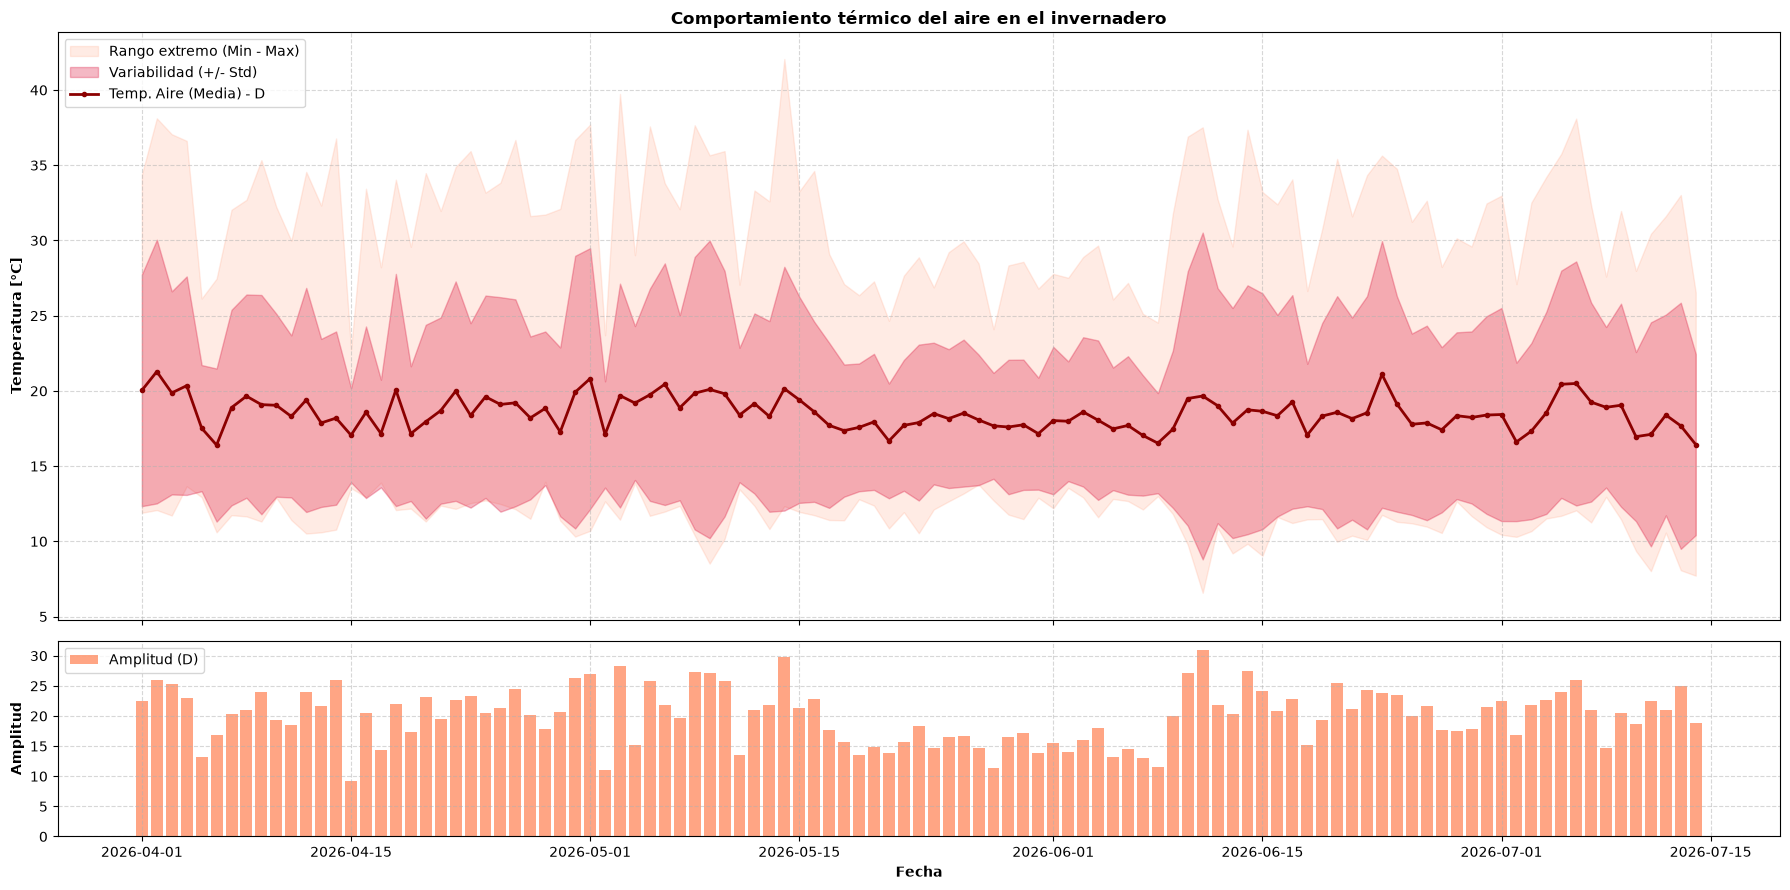

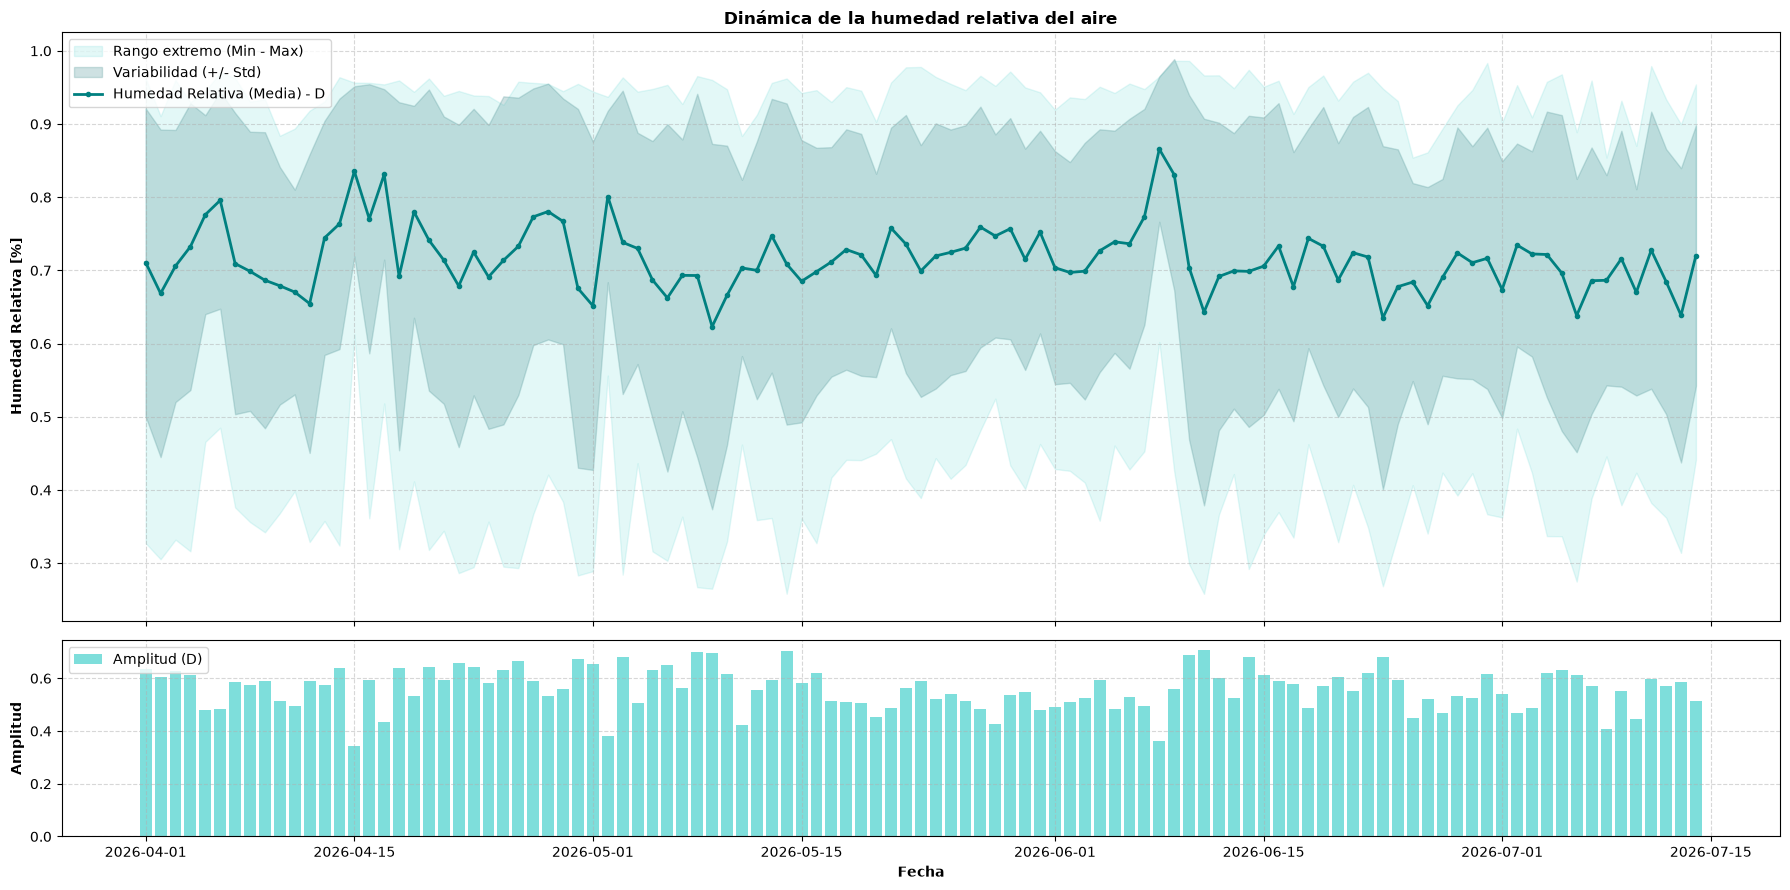

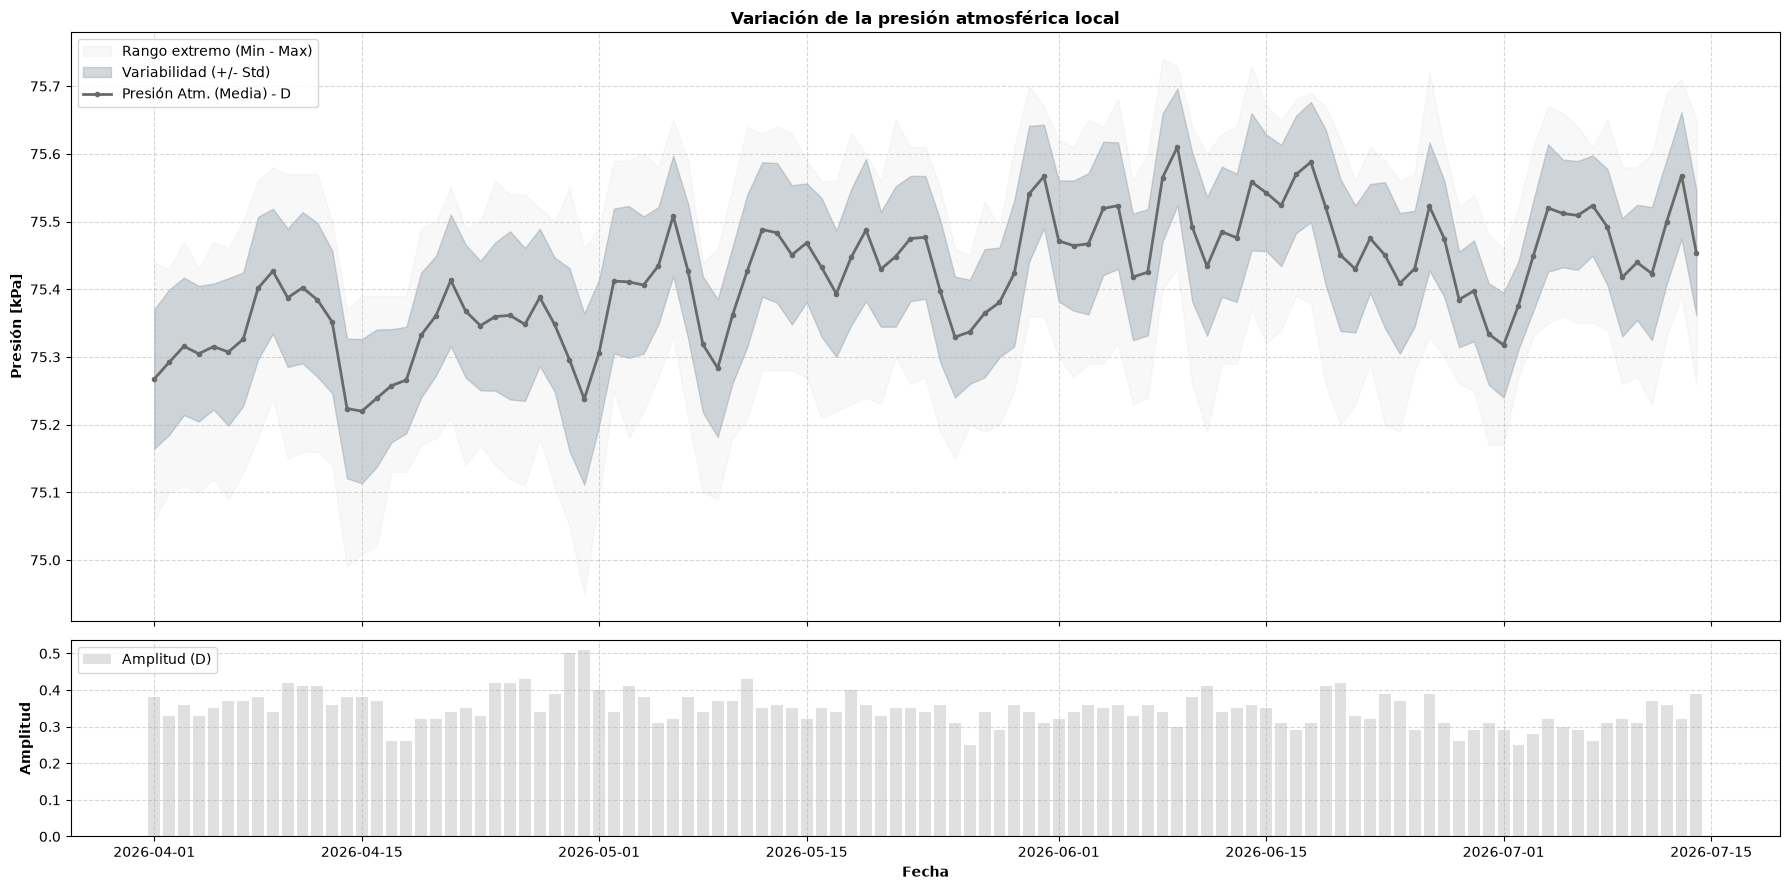

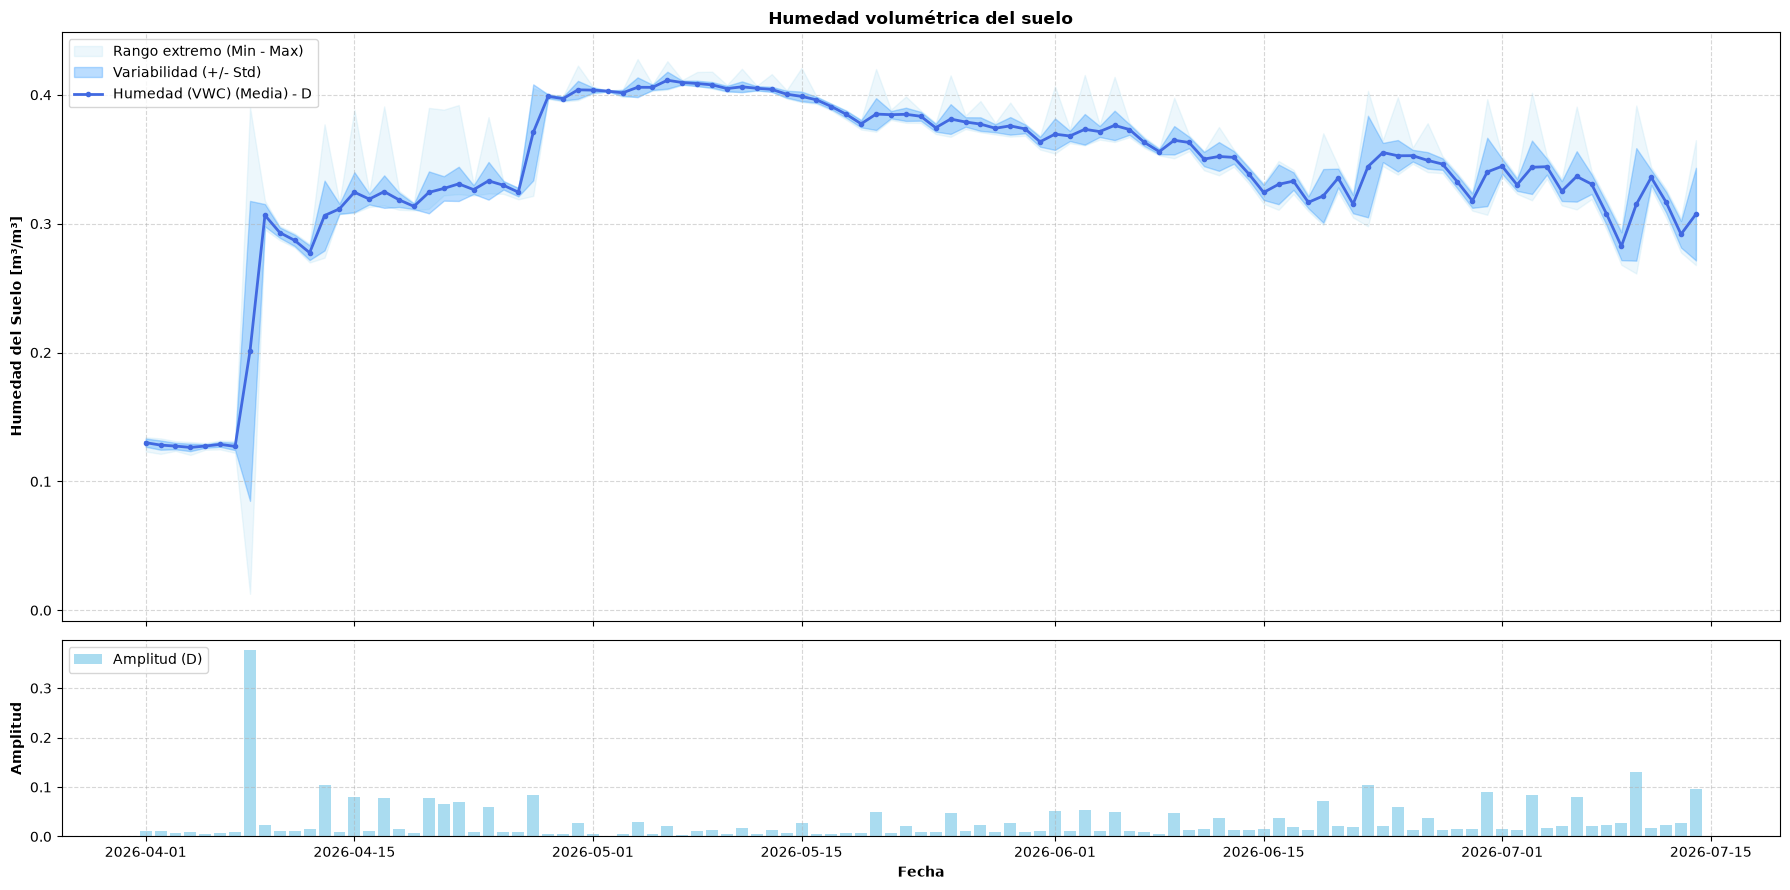

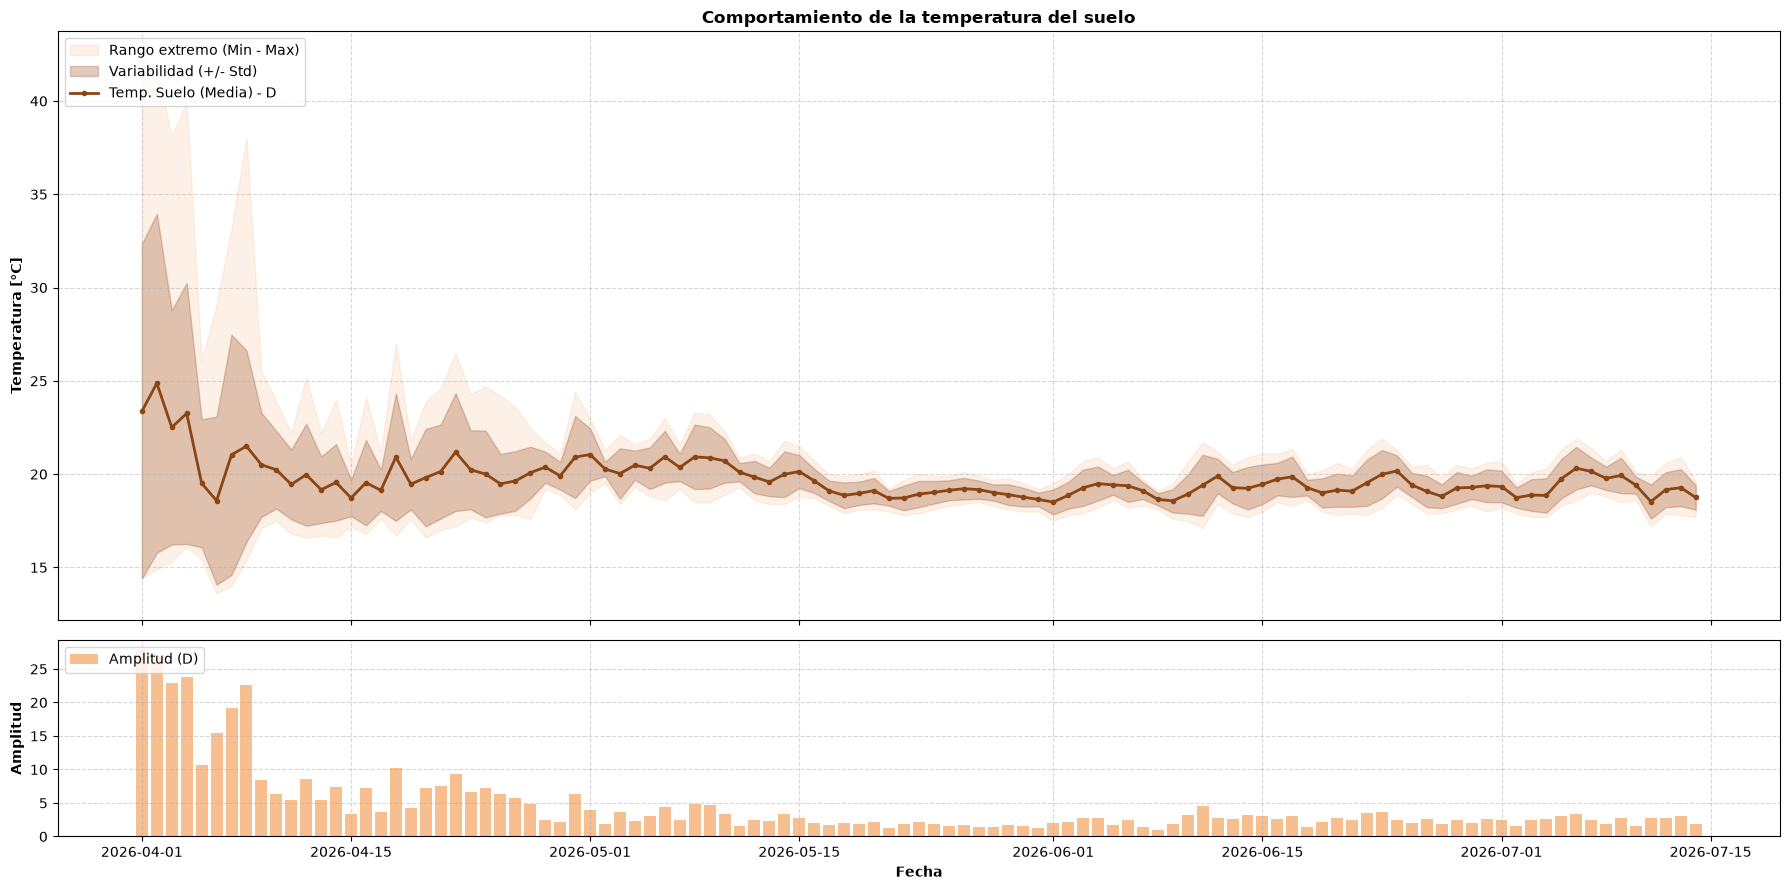

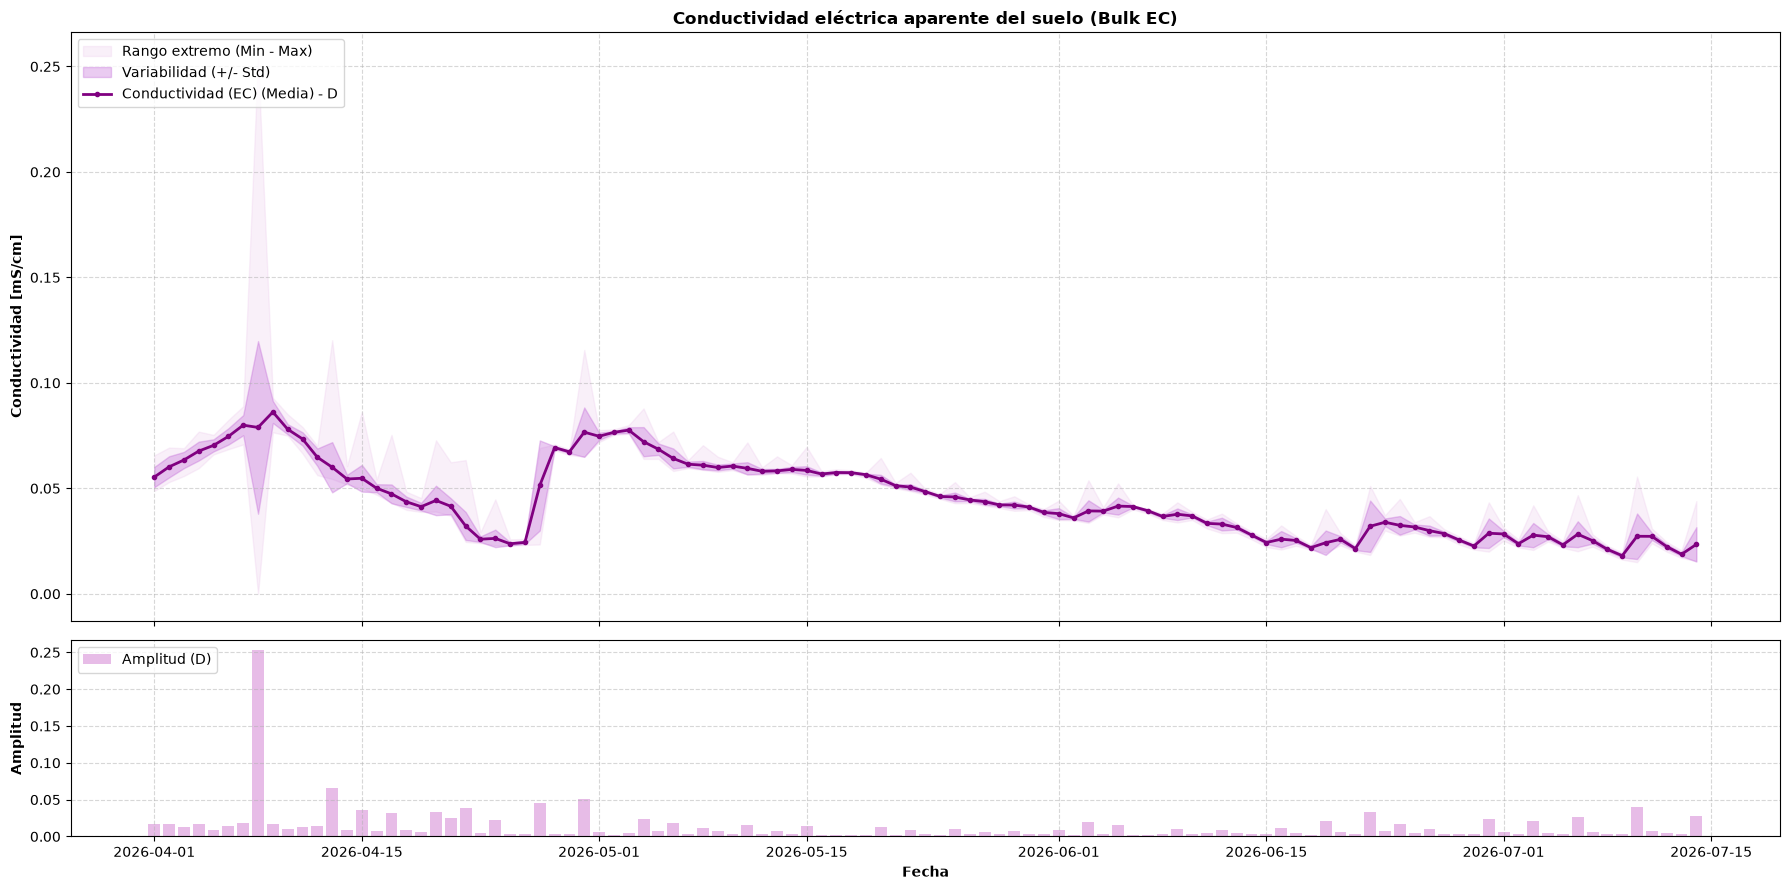

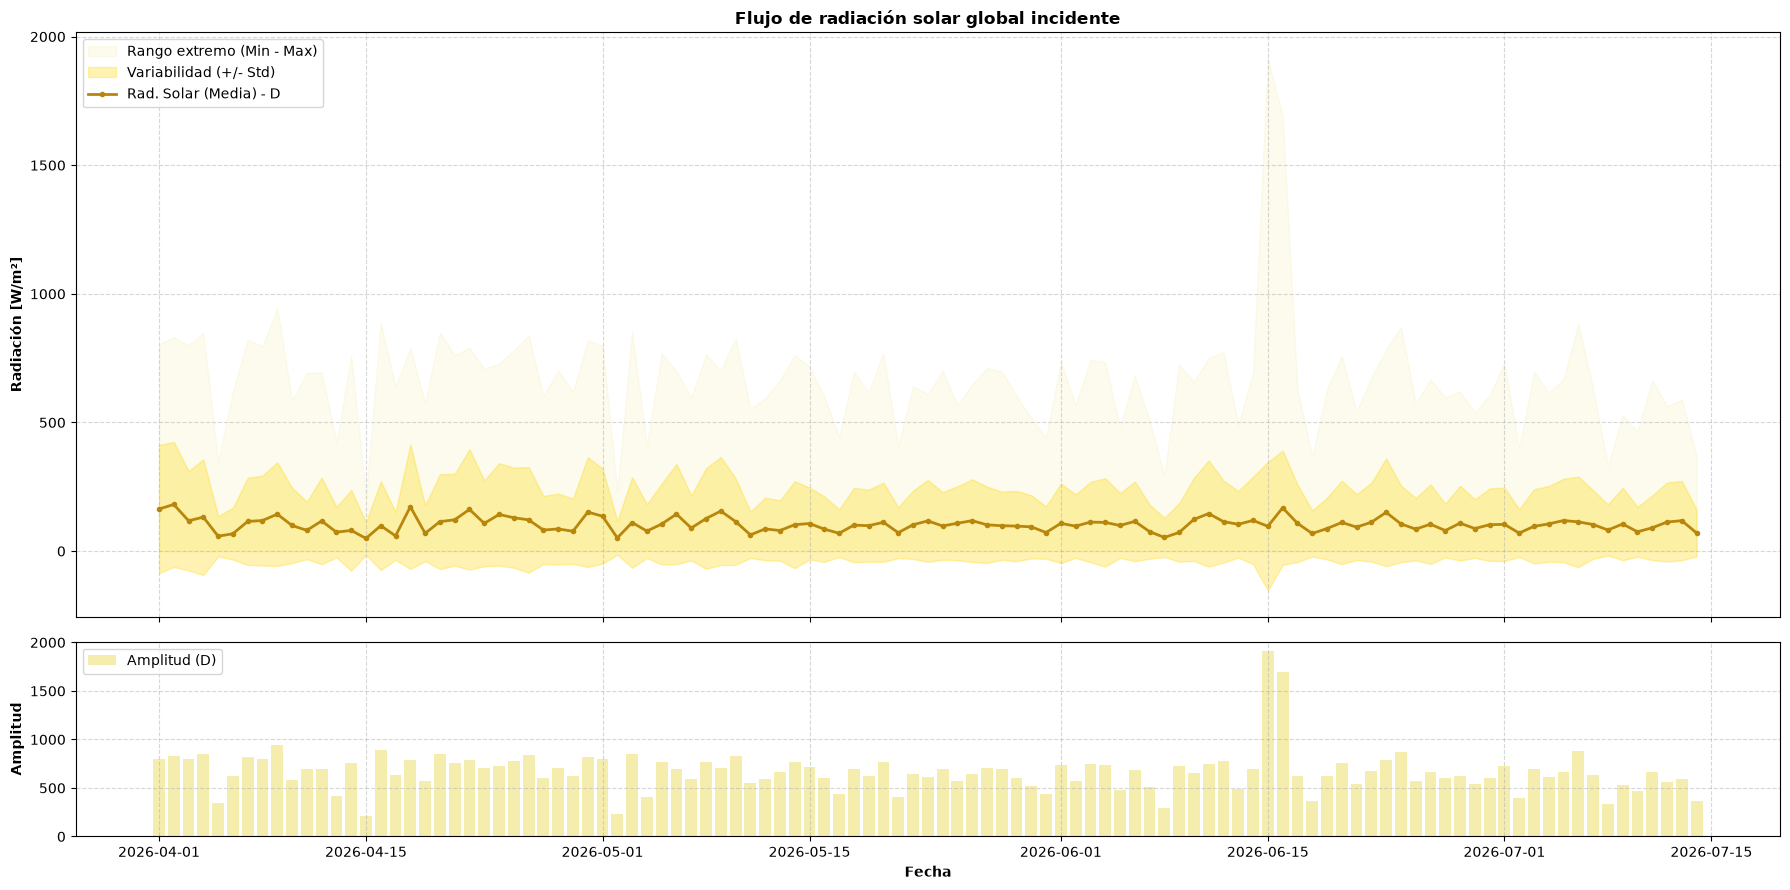

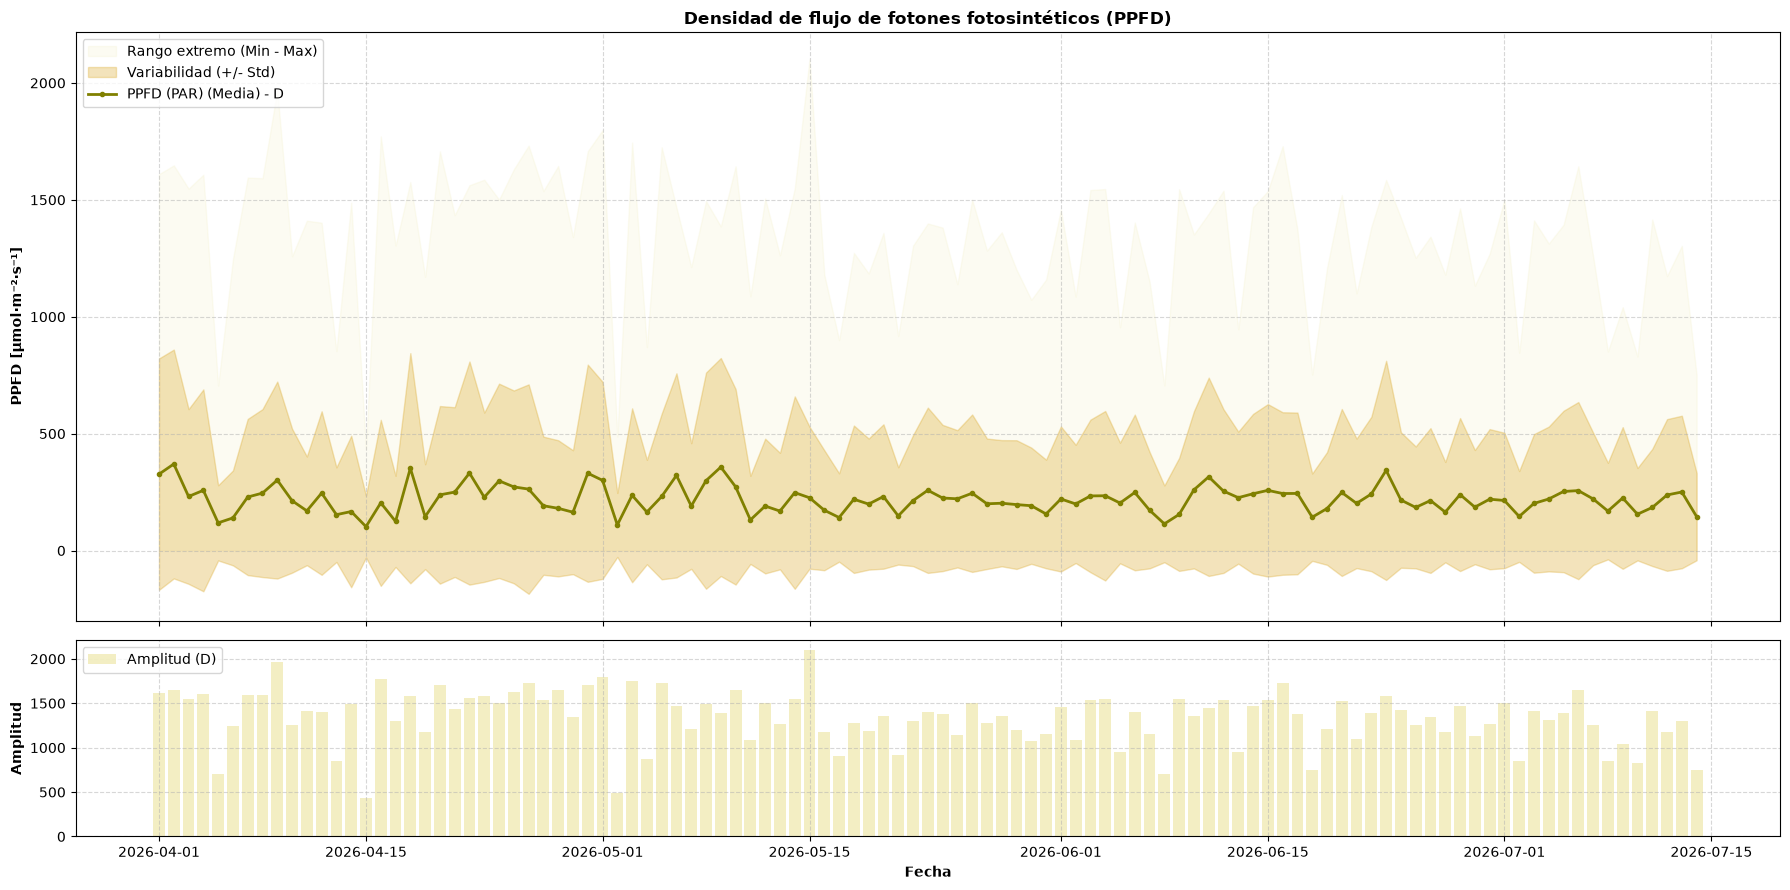

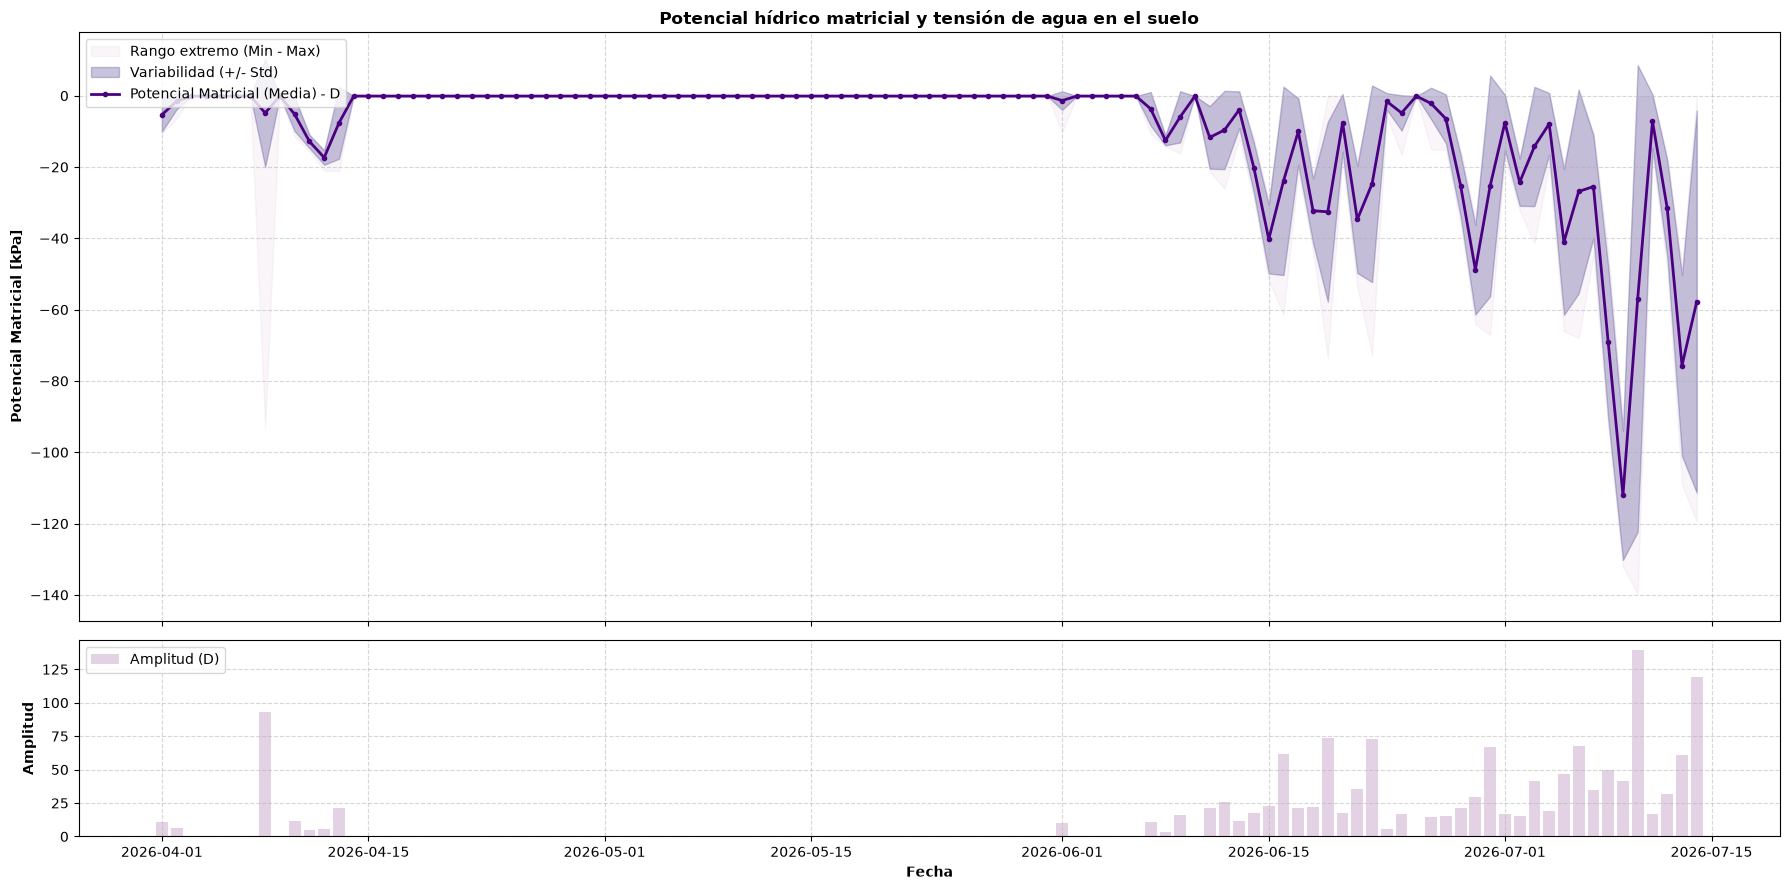

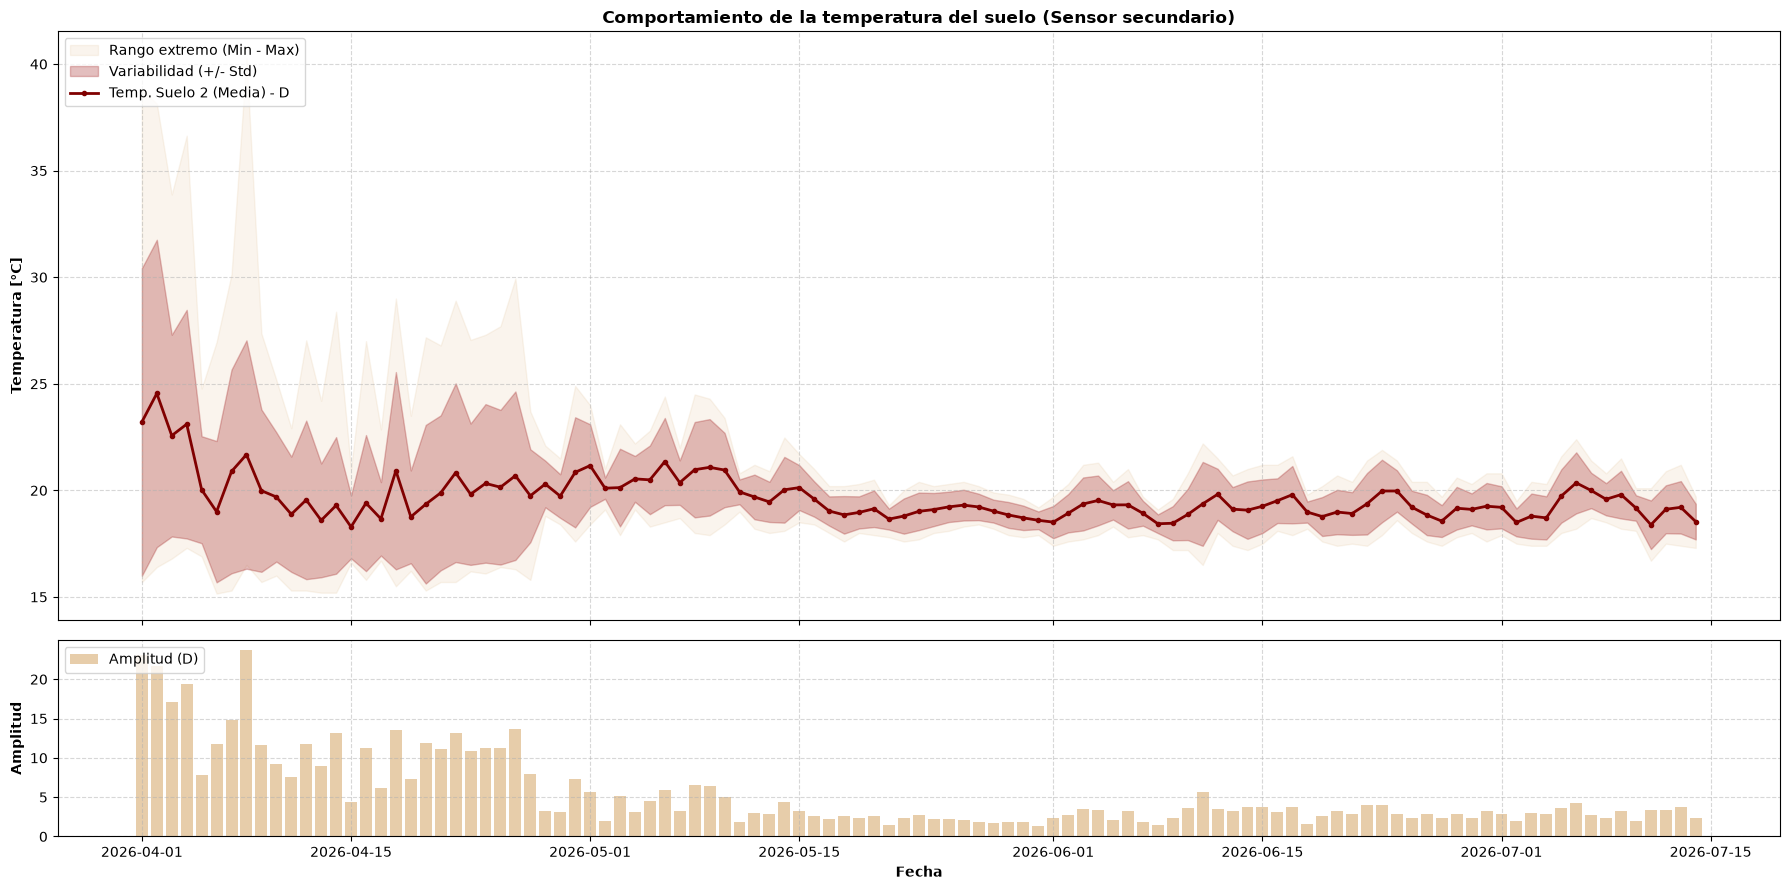

In [25]:
# ==============================================================================
# GUÍA DE FRECUENCIAS EN PANDAS (.resample() / pd.Grouper())
# Nota: Puedes anteponer números a cualquier código (ej: '15min', '6h', '2W')
# ==============================================================================

# --- MINUTOS Y HORAS (Sub-diario / Riego y Microclima) ---
# 's'     -> Segundos
# 'min'   -> Minutos (ej. '15min', '30min')
# 'h'     -> Horas (ej. '1h', '6h', '12h')

# --- DÍAS Y SEMANAS ---
# 'D'     -> Diario calendario (00:00 a 23:59)
# 'B'     -> Días hábiles / laborales (Lunes a Viernes)
# 'W'     -> Semanal (cierra los domingos por defecto)
# 'W-MON' -> Semanal iniciando en Lunes ('W-TUE', 'W-SUN', etc.)

# --- MESES, TRIMESTRES Y AÑOS (S = Inicio / E = Fin) ---
# 'MS'    -> Inicio de mes (1° del mes)
# 'ME'    -> Fin de mes (Último día del mes)
# 'QS'    -> Inicio de trimestre (1 de Ene, Abr, Jul, Oct)
# 'QE'    -> Fin de trimestre (Último día de Ene, Abr, Jul, Oct)
# 'YS'    -> Inicio de año (1 de Enero)
# 'YE'    -> Fin de año (31 de Diciembre)
# ==============================================================================

riego = False #Cambiar en caso de querer graficar los dias de reigo

df_riego_g = None

if riego:
    df_riego_g = df_riego

frecuencia_analisis = "D"

# Ciclo automatizado enviando 'frec' a la función
for variable, cfg in var.items():
    graficar_est_desc(df_est, variable, cfg, frecuencia_analisis, df_riego_g)

In [15]:
from windrose import WindroseAxes
import numpy as np

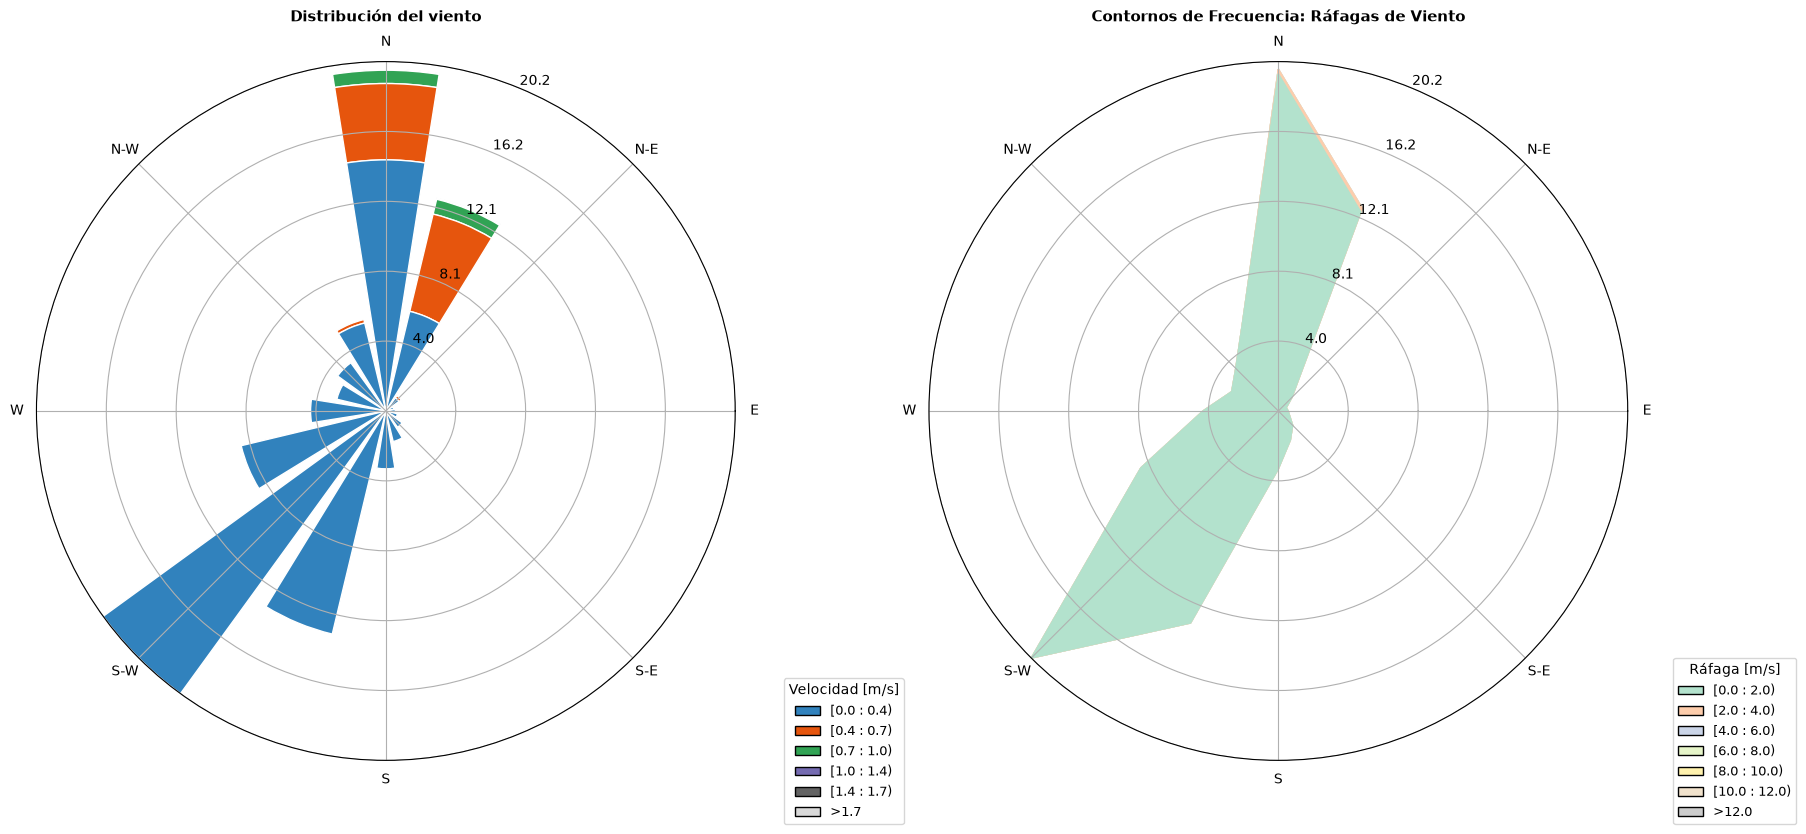

In [16]:
# https://python-windrose.github.io/windrose/usage-output.html
# Crear la figura principal
fig = plt.figure(figsize=(18, 9))

# --------------------------------------------------
# ROSA DE LOS VIENTOS: VELOCIDAD PROMEDIO DE VIENTO
# --------------------------------------------------

# Para usar dos o mas figuras en fig... es algo como una firgura compuesta
ax1 = fig.add_subplot(121, projection = "windrose") # filas = 1, columnas = 2, posición = 1

ax1.bar(
    df_est["° Wind Direction"],
    df_est["m/s Wind Speed"],
    normed = True,  # Porcentaje de frecuencia (%)
    opening = 0.8,  # Ancho de las barras
    edgecolor = "white",
    linewidth = 1,
    cmap = plt.cm.tab20c, # Para mas mapas de color https://matplotlib.org/stable/users/explain/colors/colormaps.html
)
ax1.set_title(
    "Distribución del viento",
    fontweight = "bold",
    fontsize = 11,
    pad = 10,
)
ax1.legend(
    title = "Velocidad [m/s]",
    loc = "lower right",
    bbox_to_anchor=(1.25, -0.1), #Esto corre la posicion de la leyenda con respecto al lower right
    fontsize = 9,
)

# -------------------------------------
# ROSA DE LOS VIENTOS: RÁFAGAS MÁXIMAS
# -------------------------------------
ax2 = fig.add_subplot(122, projection = "windrose") # filas = 1, columnas = 2, posición = 2

ax2.contourf(
    df_est["° Wind Direction"],
    df_est["m/s Gust Speed"],
    normed = True,
    cmap = plt.cm.Pastel2,
    bins = np.linspace(0, 12, 7), #Division de rangos para que sea 0,2,4,6,8,10,12 y los colores entre esos numeros
)

ax2.set_title(
    "Contornos de Frecuencia: Ráfagas de Viento",
    fontweight = "bold",
    fontsize = 11,
    pad = 10,
)
ax2.legend(
    title = "Ráfaga [m/s]",
    loc = "lower right",
    bbox_to_anchor = (1.25, -0.1),
    fontsize = 9,
)

plt.tight_layout()
plt.show()

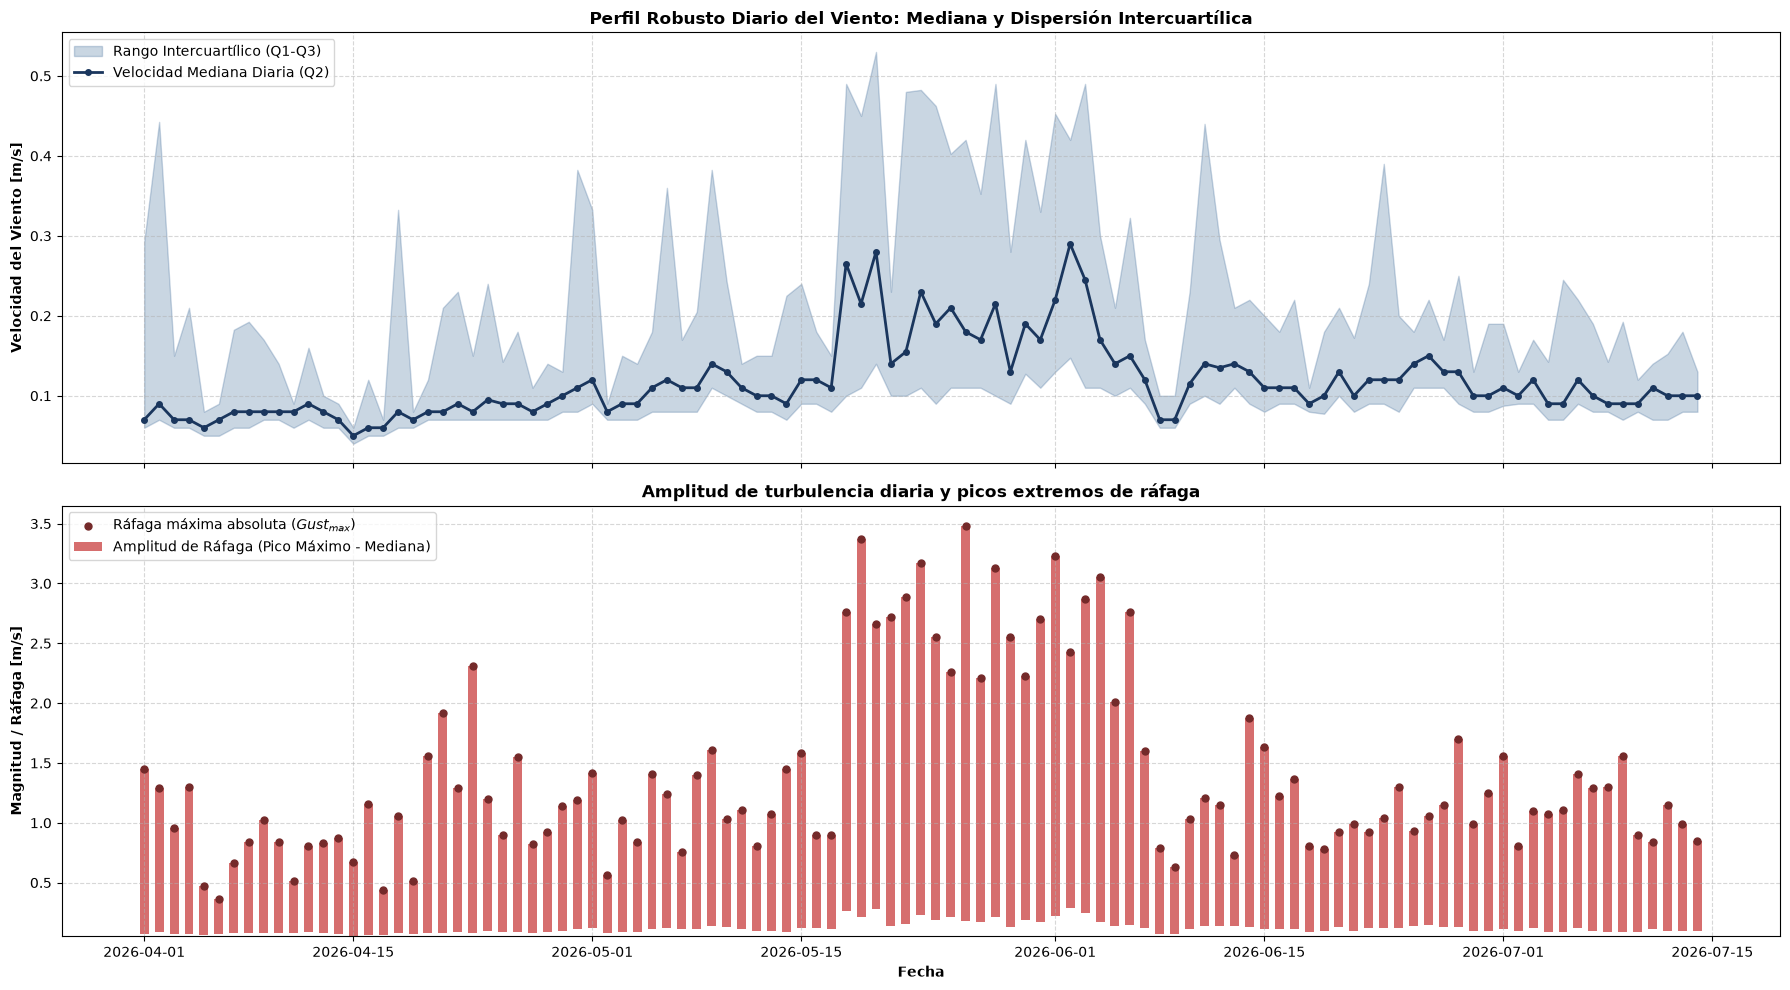

In [37]:
# Agrupación diaria y cálculo de métricas estadisticas descriptivas
df_diario_viento = (df_est.resample("D", on = "Timestamp")
    .agg(
        viento_mediana = ("m/s Wind Speed", "median"),
        viento_q25 = ("m/s Wind Speed", lambda x: x.quantile(0.25)),
        viento_q75 = ("m/s Wind Speed", lambda x: x.quantile(0.75)),
        rafaga_max = ("m/s Gust Speed", "max"),
    )
    .dropna()
)
df_diario_viento = df_diario_viento.reset_index()

# Calcular la Amplitud de Ráfaga (Diferencia entre el pico máximo y el viento medio diario)
df_diario_viento["amplitud_rafaga"] = (
    df_diario_viento["rafaga_max"] - df_diario_viento["viento_mediana"]
)

# Configuración de la figura dual
fig, (ax1, ax2) = plt.subplots(2, 1, figsize = (18, 10), sharex = True)

# -------------------------------------------------------------------------
# PANEL 1: LÍNEA DE MEDIANA + ÁREA INTERCUARTÍLICA (Q1 - Q3)
# Reemplazando la media por la mediana y la media +/- sd por el rango intercuartilico
# En el viento es mejor usar la mediana en lugar de la media.
# un valor alto, afecta significativamente la media, pero la mediana
# representa mucho mejor el comportamiento del viento ya que no se afecta por valores
# atipicamente altos.
# -------------------------------------------------------------------------
# Área sombreada (Sustituto de Media ± Std)
ax1.fill_between(
    df_diario_viento['Timestamp'],
    df_diario_viento["viento_q25"],
    df_diario_viento["viento_q75"],
    color = "#2b5c8f",
    alpha = 0.25,
    label = "Rango Intercuartílico (Q1-Q3)",
)

# Línea principal de Mediana con puntos
ax1.plot(
    df_diario_viento['Timestamp'],
    df_diario_viento["viento_mediana"],
    color = "#1a365d",
    linewidth = 2,
    marker = "o",
    markersize = 4,
    label = "Velocidad Mediana Diaria (Q2)",
)

ax1.set_ylabel("Velocidad del Viento [m/s]", fontweight = "bold", fontsize = 10)
ax1.set_title(
    "Perfil Robusto Diario del Viento: Mediana y Dispersión Intercuartílica",
    fontweight = "bold",
    fontsize = 12,
)
ax1.grid(True, linestyle = "--", alpha = 0.5)
ax1.legend(loc = "upper left", frameon = True)

# -------------------------------------------------------------------------
# PANEL 2: AMPLITUD DE RÁFAGA (RÁFAGA MÁXIMA VS MEDIANA)
# -------------------------------------------------------------------------
# Gráfico de barras/puntos para representar el impacto estructural del día
ax2.bar(
    df_diario_viento['Timestamp'],
    df_diario_viento["amplitud_rafaga"],
    bottom = df_diario_viento["viento_mediana"],
    color = "#c53030",
    alpha = 0.7,
    width = 0.6,
    label = "Amplitud de Ráfaga (Pico Máximo - Mediana)",
)

# Punto flotante con el valor exacto de la ráfaga máxima
ax2.scatter(
    df_diario_viento['Timestamp'],
    df_diario_viento["rafaga_max"],
    color = "#742a2a",
    s = 25,
    zorder = 3,
    label = "Ráfaga máxima absoluta ($Gust_{max}$)",
)

ax2.set_ylabel("Magnitud / Ráfaga [m/s]", fontweight = "bold", fontsize = 10)
ax2.set_xlabel("Fecha", fontweight = "bold", fontsize = 10)
ax2.set_title(
    "Amplitud de turbulencia diaria y picos extremos de ráfaga",
    fontweight = "bold",
    fontsize = 12,
)
ax2.grid(True, linestyle = "--", alpha = 0.5)
ax2.legend(loc = "upper left", frameon = True)

plt.tight_layout()
plt.show()